# Tuần 09 — Khái quát dữ liệu (5/7): Từ mẫu đến tổng thể và khoảng tin cậy

**UET.MAT1052 — Xác suất thống kê**

ThS. Hoàng Hữu Bách — BM. Khoa học & Kỹ thuật tính toán - Khoa Công nghệ Thông tin, VNU-UET

### Câu hỏi của buổi

Một lớp có 527 sinh viên. Giảng viên muốn biết trung bình mỗi sinh viên đã học ở trường bao nhiêu năm, nên hỏi 18 bạn ngồi hàng đầu và được trung bình $\bar x=1{,}77$ năm.

Con số 1,77 nói được gì về cả lớp? Nếu sai thì sai vì đâu? Và nếu muốn nói "trung bình cả lớp nằm trong khoảng nào", ta cần biết thêm điều gì?

### Sau buổi này, bạn làm được

- phân biệt tổng thể, mẫu, tham số và thống kê; nói được mỗi con số trong một bài toán thuộc loại nào;
- nhận ra ba nguồn chệch (chọn mẫu, đo lường, không phản hồi) và phân biệt chệch với biến thiên;
- mô phỏng phân phối mẫu của trung bình và tỉ lệ; phân biệt độ lệch chuẩn (SD) của dữ liệu với sai số chuẩn (SE) của một thống kê;
- giải thích ba tính chất của ước lượng: không chệch, vững, hiệu quả;
- lập, kiểm tra điều kiện và diễn giải khoảng tin cậy cho trung bình (z hoặc t) và cho tỉ lệ;
- tính cỡ mẫu cần thiết để biên sai số không vượt một mức cho trước.

Nội dung đáp ứng **LLO9.1–9.2/CLO3** của đề cương.

### Cần nhớ từ các buổi trước

- **Kỳ vọng và phương sai của trung bình** (Tuần 07). Nếu $X_1,\ldots, X_n$ độc lập, cùng kỳ vọng $\mu$ và phương sai $\sigma^2$ thì $E(\overline X_n)=\mu$ và $\mathrm{Var}(\overline X_n)=\sigma^2/n$.
- **Định lý giới hạn trung tâm** (Tuần 07). Với $n$ đủ lớn, $\overline X_n$ xấp xỉ $\mathcal N(\mu,\ \sigma^2/n)$ dù dữ liệu gốc không chuẩn.
- **Phân vị chuẩn** (Tuần 07). $\Phi(1{,}96)\approx0{,}975$, nên $P(-1{,}96\le Z\le1{,}96)\approx0{,}95$.
- **Phân phối $t$** (Tuần 07). Giống chuẩn tắc nhưng đuôi dày hơn; càng nhiều bậc tự do càng gần chuẩn.
- **Biến chỉ báo** (Tuần 06–07). Đếm số thành công $K$ trong $n$ lần thử Bernoulli$(p)$ độc lập thì $K\sim\operatorname{Binomial}(n, p)$, $E(K)=np$, $\mathrm{Var}(K)=np(1-p)$.

### Cách học notebook này

1. **Đọc** tình huống và phần giải tay.
2. **Đoán** kết quả trước khi chạy ô code hay mở đáp án.
3. **Chạy** ô bằng `Shift + Enter`.
4. **So sánh** kết quả với dự đoán; nếu khác, tìm xem mình đã hiểu sai ở bước nào.

Khối **Vì sao?** chứa chứng minh, có thể đọc sau. Ô có chú thích **Thử đổi** là chỗ bạn sửa tham số rồi chạy lại. Tên Ví dụ, Bài và Câu hỏi giữ đúng như slide để tiện đối chiếu.

**Thực hành vẽ:** [hướng dẫn Plotnine](./HUONG_DAN_PLOT.md). Mỗi hình có một đoạn “Đọc code vẽ” giải thích đúng các lệnh dùng ở hình đó, và một đoạn “Đọc hình” chỉ ra cần nhìn vào đâu.

## Lộ trình học

| Cách học | Nội dung cần làm |
|---|---|
| Học trên lớp | Mục 1–5: lấy mẫu và nguồn sai số, phân phối mẫu, tính chất ước lượng, khoảng tin cậy cho trung bình và tỉ lệ. |
| Tự luyện | Ví dụ 9–16 tự giải tay trước khi mở đáp án; Câu hỏi diễn giải; Bài 1–5 với dữ liệu CSV ở mục 6. |
| Đọc sâu | Các khối **Vì sao?**: chứng minh $E(\bar X)=\mu$, vì sao $S^2$ chia $n-1$, rút ra công thức khoảng tin cậy, công thức cỡ mẫu, hiệu chỉnh tổng thể hữu hạn. |

Chạy từ đầu bằng **Restart Kernel and Run All Cells** trước khi học, để mọi bảng và hình khớp với chữ trong bài.

### Đi đến các phần

[1. Cách chọn người quyết định phạm vi kết luận](#muc-1) · [2. Mỗi điểm trong phân phối mẫu là một thống kê](#muc-2) · [3. Ước lượng tốt là tính chất của một quy trình](#muc-3) · [4. Khoảng tin cậy cho trung bình](#muc-4) · [5. Khoảng tin cậy cho tỉ lệ và cỡ mẫu](#muc-5) · [6. Bài tập áp dụng với dữ liệu thật](#muc-6)

## Ký hiệu dùng trong buổi này

| Ký hiệu | Đọc là | Nghĩa | Ví dụ trong bài |
|---|---|---|---|
| $N$, $n$ | N lớn, n nhỏ | cỡ tổng thể, cỡ mẫu | $N=527$, $n=18$ |
| $\mu$, $\sigma$ | muy, xích-ma | trung bình và độ lệch chuẩn của **tổng thể** (tham số, cố định, thường chưa biết) | $\mu$ = số năm học trung bình của 527 sinh viên |
| $p$ | p | tỉ lệ của tổng thể | $p$ = tỉ lệ người ủng hộ điện mặt trời |
| $\bar X$, $\widehat P$, $S^2$ | X ngang, P mũ, S bình phương | trung bình, tỉ lệ, phương sai mẫu **trước khi** lấy mẫu: là biến ngẫu nhiên | $\bar X$ có phân phối mẫu riêng |
| $\bar x$, $\hat p$, $s$ | x ngang, p mũ, s nhỏ | các giá trị **đã tính** từ một mẫu cụ thể | $\bar x=1{,}77$; $\hat p=0{,}887$ |
| $\theta$, $\hat\theta$ | tê-ta, tê-ta mũ | tham số tổng quát và ước lượng của nó | $\theta=\mu$, $\hat\theta=\bar X$ |
| $SE(T)$ | sai số chuẩn của T | độ lệch chuẩn của thống kê $T$ khi lặp lại việc lấy mẫu | $SE(\bar X)=\sigma/\sqrt n$ |
| $1-\alpha$ | một trừ an-pha | mức tin cậy; $\alpha$ là phần còn lại | $1-\alpha=0{,}95$, $\alpha=0{,}05$ |
| $z_{\alpha/2}$ hay $z^*$ | z an-pha chia hai, z sao | giá trị tới hạn chuẩn: $P(Z\le z^*)=1-\alpha/2$ | $z^*\approx1{,}96$ với mức 95% |
| $t_{\alpha/2,\, n-1}$ hay $t^*$ | t sao với n trừ một bậc tự do | giá trị tới hạn của phân phối $t_{n-1}$ | $t^*\approx2{,}131$ khi $n=16$ |
| $E$ | biên sai số | nửa độ rộng của khoảng tin cậy | $E=1{,}96\cdot5/\sqrt{50}\approx1{,}39$ cm |

**Chữ Hy Lạp và chữ Latin.** Chữ Hy Lạp ($\mu,\sigma,\theta$) và chữ $p$ không dấu chỉ đại lượng của **tổng thể**. Chữ có dấu ngang hoặc dấu mũ ($\bar x,\hat p,\hat\theta$) và chữ $s$ chỉ đại lượng tính từ **mẫu**. Chữ in hoa ($\bar X$, $S$) là thống kê khi chưa lấy mẫu, còn có thể nhận nhiều giá trị; chữ thường ($\bar x$, $s$) là con số đã tính ra.

**Cách viết khác.** Slide viết $z_{\alpha/2}$, nhiều sách viết $z^*$ hoặc $z_{1-\alpha/2}$; cả ba cùng chỉ một số (≈1,96 ở mức 95%). Slide dùng dấu chấm thập phân (1.77); notebook dùng dấu phẩy (1,77) trong lời văn, còn code Python luôn dùng dấu chấm.

### Thiết lập tính toán

- `numpy` (`np`): tạo mảng số và sinh số ngẫu nhiên; `pandas` (`pd`): bảng dữ liệu; `scipy.stats` (`stats`): xác suất và phân vị của các phân phối (`stats.norm`, `stats.t`); `statsmodels`: dùng ở mục 5 để lập khoảng cho tỉ lệ.
- `DATA = Path('datasets')`: thư mục chứa các tệp CSV đi kèm. Notebook phải nằm cạnh thư mục này.
- `rng = np.random.default_rng(42)`: bộ sinh số ngẫu nhiên với seed 42. Chạy lại từ đầu sẽ cho đúng các con số in trong bài. Kết quả mô phỏng có sai số ngẫu nhiên; kết quả công thức thì không.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display

DATA = Path('datasets')
assert DATA.is_dir(), 'Hãy mở notebook từ thư mục có datasets/ đi kèm.'
rng = np.random.default_rng(42)
pd.set_option('display.precision', 5)
pd.set_option('display.max_columns', 12)

from plotnine import (ggplot, aes, geom_histogram, geom_line, geom_point, geom_col,
    geom_vline, geom_hline, geom_segment, geom_area, geom_tile, geom_text,
    facet_wrap, labs, theme_minimal, theme, element_text, scale_color_manual,
    scale_fill_manual, coord_cartesian)

<a id="muc-1"></a>

## 1. Cách chọn người quyết định phạm vi kết luận

### Bốn khái niệm cần tách bạch

| Khái niệm | Định nghĩa | Trong ví dụ lớp học |
|---|---|---|
| **Tổng thể** | toàn bộ các đơn vị mà ta muốn kết luận, cỡ $N$ | 527 sinh viên của lớp |
| **Mẫu** | những đơn vị thực sự được quan sát, cỡ $n$ | 18 sinh viên được hỏi |
| **Tham số** | một con số tóm tắt tổng thể | $\mu$ = số năm học trung bình của 527 người |
| **Thống kê** | một con số tính được từ mẫu | $\bar x=1{,}77$ năm, trung bình của 18 người |

Tham số là cố định nhưng ta không biết. Thống kê thì ta tính được, nhưng **đổi mẫu là đổi giá trị**. Cả buổi hôm nay xoay quanh một câu hỏi: dùng một thống kê để đoán một tham số thì có thể sai bao nhiêu, và sai vì đâu.

Có hai kiểu sai khác hẳn nhau:

- **Chệch (bias)**: cách lấy dữ liệu làm kết quả lệch **có hệ thống** về một phía. Lặp lại bao nhiêu lần cũng lệch như thế.
- **Biến thiên (variability)**: kết quả thay đổi ngẫu nhiên từ mẫu này sang mẫu khác. Lặp lại nhiều lần thì các kết quả rải quanh một tâm.

Cách chọn mẫu ảnh hưởng đến cả hai.

### Năm cách lấy mẫu ngẫu nhiên

**Ngẫu nhiên đơn (simple random sampling, SRS).** Lập danh sách toàn bộ tổng thể (gọi là *khung lấy mẫu*), đánh số từng đơn vị, rồi bốc ngẫu nhiên $n$ số không lặp lại (bằng phần mềm, bảng số ngẫu nhiên hoặc bốc thăm). Định nghĩa đầy đủ: **mọi nhóm gồm $n$ đơn vị đều có cùng khả năng được chọn**. Điều này mạnh hơn "mỗi người có cùng xác suất được chọn". Ví dụ phản chứng: lớp có hai nhóm bằng nhau, tung đồng xu để chọn nguyên một nhóm. Mỗi người có xác suất 1/2, nhưng không bao giờ có mẫu gồm người của cả hai nhóm, nên đây không phải SRS.

**Hệ thống (systematic).** Xếp tổng thể theo một thứ tự, tính bước nhảy $k=N/n$, chọn ngẫu nhiên điểm bắt đầu $r$ trong $1,\ldots, k$, rồi lấy các vị trí $r,\ r+k,\ r+2k,\ldots$ Ví dụ của slide: chọn 5 trong 20 khách hàng, $k=20/5=4$, $r=3$, được các vị trí 3, 7, 11, 15, 19. Cách này dễ làm, nhưng nếu danh sách có chu kỳ trùng với $k$ (ví dụ cứ 4 người lại có một trưởng nhóm) thì mẫu có thể lệch.

**Phân tầng (stratified).** Chia tổng thể thành các *tầng* sao cho trong mỗi tầng các đơn vị khá giống nhau (theo khóa học, giới tính, vùng...), rồi lấy mẫu ngẫu nhiên **trong từng tầng**. Ví dụ: khảo sát sinh viên ba khóa, chia danh sách theo khóa và chọn trong cả ba khóa để khóa nào cũng có mặt. Khi gộp kết quả, mỗi tầng phải được tính theo đúng tỉ trọng của nó trong tổng thể.

**Theo cụm (cluster).** Chia tổng thể thành các *cụm* có sẵn (khu phố, lớp học, thôn), chọn ngẫu nhiên một số cụm, rồi khảo sát toàn bộ hoặc một phần đơn vị trong các cụm đó. Ở bước chọn, đơn vị được chọn là **cụm**, không phải từng người. Ví dụ: phường có 20 khu phố, cần khoảng 100 hộ, chọn ngẫu nhiên 5 khu phố rồi khảo sát tất cả các hộ trong 5 khu phố đó. Lưu ý: số hộ thu được phụ thuộc vào quy mô 5 khu phố được chọn, nên không chắc đúng 100.

**Nhiều bậc (multistage).** Chọn lần lượt qua nhiều cấp. Ví dụ của slide: chọn 5 huyện, mỗi huyện 4 xã, mỗi xã 5 ấp, mỗi ấp 10 hộ, được $5\times4\times5\times10=1000$ hộ.

| Thiết kế | Đơn vị được bốc ngẫu nhiên | Điểm mạnh | Cần cẩn thận |
|---|---|---|---|
| Ngẫu nhiên đơn | từng cá thể | đơn giản, công thức của buổi này dùng trực tiếp | cần danh sách đầy đủ |
| Hệ thống | điểm bắt đầu | dễ làm trên danh sách dài | danh sách có chu kỳ |
| Phân tầng | cá thể trong từng tầng | mọi nhóm đều có mặt | gộp theo đúng tỉ trọng |
| Cụm | cả cụm | rẻ, đi lại ít | người trong cùng cụm thường giống nhau, nên mẫu chứa ít thông tin hơn SRS cùng cỡ |
| Nhiều bậc | lần lượt từng cấp | dùng cho tổng thể lớn, phân cấp | phải ghi lại xác suất chọn ở mỗi bậc |

Các công thức sai số chuẩn trong buổi này được viết cho **mẫu ngẫu nhiên đơn** (hoặc các lần thử độc lập). Với mẫu phân tầng hay mẫu cụm, công thức khác đi; phần đó thuộc môn chọn mẫu điều tra.

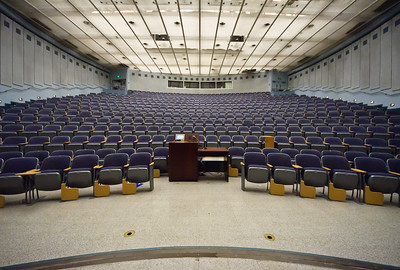

*Hình tham khảo 9.0: Giảng đường Pimentel. Nguồn: STAT 20 bản dịch tiếng Việt, mục 5.1, hình nhúng trong học liệu gốc.*

Một giảng đường lớn như thế này là tình huống của câu hỏi mở đầu. Người ngồi hàng đầu dễ hỏi nhất, nhưng họ có thể không giống phần còn lại của lớp.

Ô dưới làm lại hai cách chọn của slide trên danh sách 20 mã số: một mẫu ngẫu nhiên đơn 5 mã, và mẫu hệ thống với bước $k=4$, bắt đầu tại $r=3$. Dòng cuối kiểm tra phép nhân của ví dụ nhiều bậc.

- `rng.choice(ids, size=5, replace=False)`: bốc 5 phần tử khác nhau từ `ids`.
- `np.arange(r, 21, 4)`: các số từ `r` đến 20, cách nhau 4.

**Bạn đoán trước:** chạy lại ô này (không khởi động lại kernel), cột nào đổi, cột nào giữ nguyên?

In [2]:
ids = np.arange(1, 21)
srs = rng.choice(ids, size=5, replace=False)
r = 3  # Thử đổi: điểm bắt đầu từ 1 đến 4
systematic = np.arange(r, 21, 4)
display(pd.DataFrame({'SRS': np.sort(srs), 'Hệ thống': systematic}))
print('Số hộ trong ví dụ nhiều bậc:', 5*4*5*10)

,SRS,Hệ thống
0,2,3
1,9,7
2,12,11
3,14,15
4,20,19


Số hộ trong ví dụ nhiều bậc: 1000


Cột SRS đổi mỗi lần chạy, vì `rng` sinh số mới. Cột hệ thống chỉ đổi khi bạn sửa `r`: với $k=4$ chỉ có 4 mẫu hệ thống khả dĩ ($r=1,2,3,4$), trong khi số mẫu ngẫu nhiên đơn cỡ 5 từ 20 người là $\binom{20}{5}=15\,504$.

### Ba nguồn chệch và hai nguồn biến thiên

Năm ví dụ dưới đây của slide lần lượt minh họa chệch chọn mẫu, chệch đo lường, chệch không phản hồi, biến thiên lấy mẫu và biến thiên đo lường. Với mỗi ví dụ, hãy trả lời hai câu: lỗi xảy ra **ở bước nào** (chọn ai, đo thế nào, ai trả lời)? Lấy thêm dữ liệu theo **cùng cách cũ** có sửa được không?

### Ví dụ 1

Giảng viên hỏi 18 sinh viên ngồi hàng đầu để ước lượng số năm học trung bình của cả lớp và được $\bar x=1{,}77$. Giả sử sinh viên năm nhất hay ngồi phía trước hơn. (1) Đây là loại mẫu gì? (2) 1,77 có xu hướng cao hơn hay thấp hơn $\mu$? (3) Hỏi thêm nhiều người ở hàng đầu có sửa được không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.* Đây là **mẫu thuận tiện**: chọn người vì họ dễ hỏi, không phải vì được bốc ngẫu nhiên.

*Câu 2.* Năm nhất có số năm học nhỏ nhất. Nếu họ chiếm tỉ lệ ở hàng đầu cao hơn trong cả lớp, trung bình mẫu sẽ có xu hướng **thấp hơn** $\mu$. Đây là **chệch chọn mẫu**.

*Câu 3.* Không. Hỏi 50 người hàng đầu thay vì 18 người vẫn ưu tiên đúng nhóm đó. Cỡ mẫu lớn hơn làm kết quả ít dao động hơn, nhưng tâm của nó vẫn lệch. Muốn sửa phải đổi **cách chọn**, ví dụ bốc ngẫu nhiên 18 mã số từ danh sách lớp.

</details>

### Ví dụ 2

Giả sử một số sinh viên năm nhất khai mình là năm hai vì ngại bị coi là quá háo hức. Sai số phát sinh ở bước nào? Kết quả lệch về phía nào?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

Người được chọn có thể hoàn toàn đúng, nhưng **giá trị ghi lại bị sai**. Đây là **chệch đo lường**. Các câu trả lời sai đều đẩy số năm lên, nên $\bar x$ có xu hướng cao hơn thực tế.

Cách giảm: viết câu hỏi rõ ràng, cho trả lời ẩn danh, khảo sát thử trước, hoặc đối chiếu với hồ sơ của trường. Với thiết bị đo, cách tương ứng là hiệu chỉnh thiết bị.

</details>

### Ví dụ 3

Nhà trường chọn ngẫu nhiên 1.000 sinh viên và gửi khảo sát về mức căng thẳng. Chỉ 120 người trả lời. Khi nào việc 880 người không trả lời làm kết quả bị chệch?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

Khi **khả năng trả lời liên quan đến chính điều đang đo**. Ví dụ người đang rất căng thẳng có thể không có thời gian trả lời; khi đó 120 người trả lời ít căng thẳng hơn trung bình và kết quả bị kéo xuống. Đây là **chệch không phản hồi**.

Nếu việc trả lời hay không gần như ngẫu nhiên, không liên quan đến mức căng thẳng, thì 120 người vẫn là một mẫu ngẫu nhiên nhỏ hơn: kết quả dao động nhiều hơn nhưng không lệch. Tỉ lệ phản hồi thấp (12%) vì vậy là **dấu hiệu cảnh báo**, không tự nó cho biết độ chệch lớn bao nhiêu.

Cách giảm: nhắc lại người chưa trả lời, rút ngắn bảng hỏi, dùng trọng số dựa trên thông tin đã biết về cả 1.000 người (khóa, ngành...).

</details>

### Ví dụ 4

Mỗi ngày chọn ngẫu nhiên 18 sinh viên trong lớp và tính $\bar x$. Ba ngày được 1,77; 2,10; 2,35. Ba con số khác nhau có chứng tỏ cách chọn sai không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

Không. Mỗi ngày là một mẫu ngẫu nhiên khác, nên $\bar x$ khác nhau là bình thường. Đây là **biến thiên lấy mẫu**: thay đổi của một thống kê từ mẫu này sang mẫu khác, dù cách chọn không chệch.

Nếu lặp lại rất nhiều ngày và vẽ histogram của các $\bar x$, ta được **phân phối mẫu** của $\bar X$ (mục 2). Độ lệch chuẩn của phân phối đó được gọi là **sai số chuẩn** $SE(\bar X)$.

</details>

### Ví dụ 5

Đo huyết áp của cùng một người nhiều lần cho kết quả khác nhau. Nêu các nguyên nhân gây dao động, và phân biệt chúng với trường hợp máy đo luôn đọc cao hơn 5 mmHg.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

Tư thế, trạng thái của người được đo, sai số ngẫu nhiên của dụng cụ, cách người đo đọc và làm tròn đều làm các lần đo **rải ra** quanh giá trị thật. Đó là **biến thiên đo lường**. Đo nhiều lần rồi lấy trung bình sẽ giảm được dao động này.

Máy luôn đọc cao 5 mmHg là **chệch đo lường**: mọi lần đo đều lệch cùng một phía. Lấy trung bình 100 lần đo vẫn cao hơn thật khoảng 5 mmHg. Phải hiệu chỉnh máy.

</details>

### Chệch và biến thiên là hai trục khác nhau

| | Biến thiên nhỏ | Biến thiên lớn |
|---|---|---|
| **Không chệch** | các kết quả tụm sát quanh giá trị thật | rải rộng nhưng tâm đúng |
| **Chệch** | tụm sát quanh một điểm **sai** | vừa rải rộng vừa lệch tâm |

Tăng cỡ mẫu chỉ di chuyển theo cột: từ "biến thiên lớn" sang "biến thiên nhỏ". Nó không chuyển được từ hàng "chệch" sang hàng "không chệch".

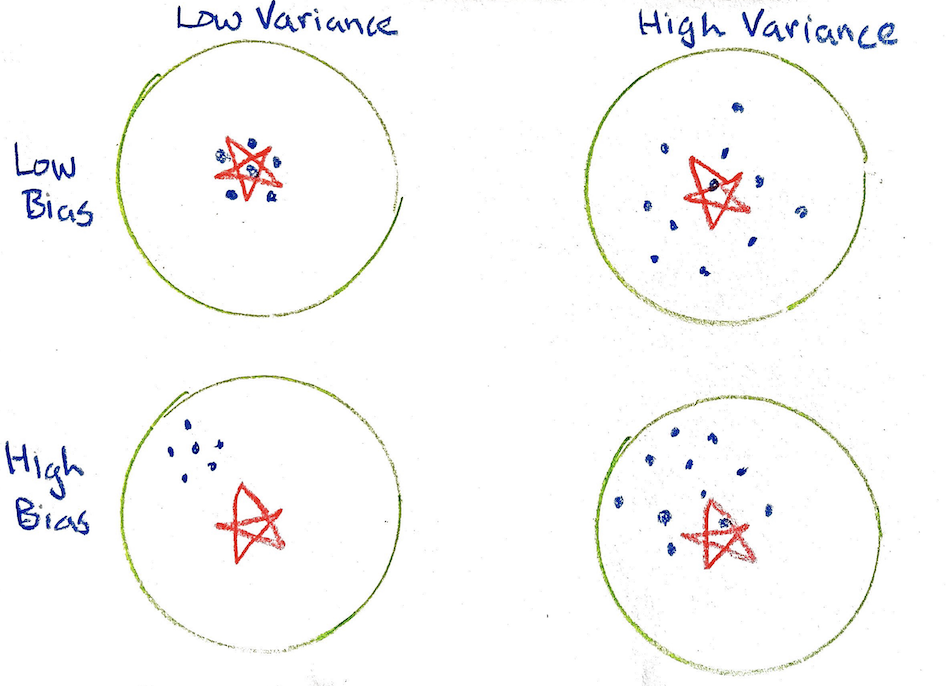

*Hình tham khảo 9.2: Độ chệch và biến thiên là hai đặc điểm khác nhau. Nguồn: STAT 20 bản dịch tiếng Việt, mục 5.1, hình nhúng trong học liệu gốc.*

Mỗi bia là một quy trình, mỗi chấm là kết quả của một lần lặp. Hãy chỉ ra trên hình: bia nào có tâm đúng nhưng chấm rải rộng, bia nào chấm tụm sát nhưng lệch khỏi hồng tâm.

**Thí nghiệm: lấy mẫu chệch rồi tăng cỡ mẫu.** Ô dưới dựng một lớp *giả lập* 527 sinh viên: 250 năm nhất, 220 năm hai, 40 năm ba, 17 năm tư. Trung bình thật của lớp giả lập này là

$$\mu=\frac{250\cdot1+220\cdot2+40\cdot3+17\cdot4}{527}=\frac{878}{527}\approx1{,}666 \text{ năm}.$$

Ta so sánh hai cách chọn, mỗi cách lặp 1.500 lần, với $n=18$ và $n=72$:

- **SRS**: mọi sinh viên có cùng khả năng được chọn.
- **Ưu tiên hàng đầu**: khả năng được chọn tỉ lệ với $5-\text{năm học}$, nên năm nhất (trọng số 4) dễ được chọn gấp 4 lần năm tư (trọng số 1). Biến `prob_front` chứa các xác suất này, đã chia cho tổng để cộng lại bằng 1.

Mỗi lần lặp tính một $\bar x$. Bảng in ra trung bình (`mean`) và độ lệch chuẩn (`std`) của 1.500 giá trị $\bar x$ ấy.

**Bạn đoán trước:** với cách "ưu tiên hàng đầu", tăng $n$ từ 18 lên 72 thì cột `mean` có tiến về 1,666 không? Cột `std` thay đổi thế nào?

In [3]:
# Mô phỏng minh họa, không phải danh sách 527 sinh viên thật.
population_year = np.repeat([1,2,3,4], [250,220,40,17])
prob_front = (5 - population_year).astype(float)
prob_front /= prob_front.sum()
rows = []
for n in [18, 72]:
    for design in ['SRS', 'Ưu tiên hàng đầu']:
        values = np.array([rng.choice(population_year, n, replace=False,
            p=None if design=='SRS' else prob_front).mean() for _ in range(1500)])
        rows.append(pd.DataFrame({'mean_year':values,'design':design,'n':str(n)}))
sampling_bias = pd.concat(rows, ignore_index=True)
display(sampling_bias.groupby(['n','design'])['mean_year'].agg(['mean','std']))
print('Trung bình tổng thể mô phỏng:', population_year.mean())

mean      std
n  design                            
18 SRS               1.66833  0.17848
   Ưu tiên hàng đầu  1.49937  0.14644
72 SRS               1.66619  0.08011
   Ưu tiên hàng đầu  1.50466  0.07081

Trung bình tổng thể mô phỏng: 1.666034155597723


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(sampling_bias, aes(...))` lấy bảng `sampling_bias`; trong `aes`, trục ngang là cột `mean_year`. `fill='design'` cho mỗi giá trị của cột `design` một màu riêng; `alpha=0.6` làm cột trong suốt để thấy phần chồng lên nhau. `geom_histogram(bins=30)` chia trục ngang thành 30 khoảng bằng nhau rồi đếm số dòng của bảng rơi vào mỗi khoảng; chiều cao cột là số đếm. `geom_vline(xintercept=...)` vẽ đường đứt đoạn tại `population_year.mean()`. `facet_wrap('~n', scales='free')` vẽ mỗi giá trị của `n` vào một ô riêng; `scales='free'` cho mỗi ô thang trục riêng, nên so các ô bằng số ghi trên trục, không bằng độ cao trên màn hình.

**Đọc hình.** Mỗi ô là một cỡ mẫu. Trong mỗi ô có hai histogram chồng lên nhau, mỗi histogram gồm 1.500 giá trị $\bar x$. Đường đứt đoạn là $\mu\approx1{,}666$. So hai ô: histogram nào hẹp lại? Histogram nào vẫn nằm lệch sang trái đường đứt đoạn?

<!-- branch-plot-instructions: end -->

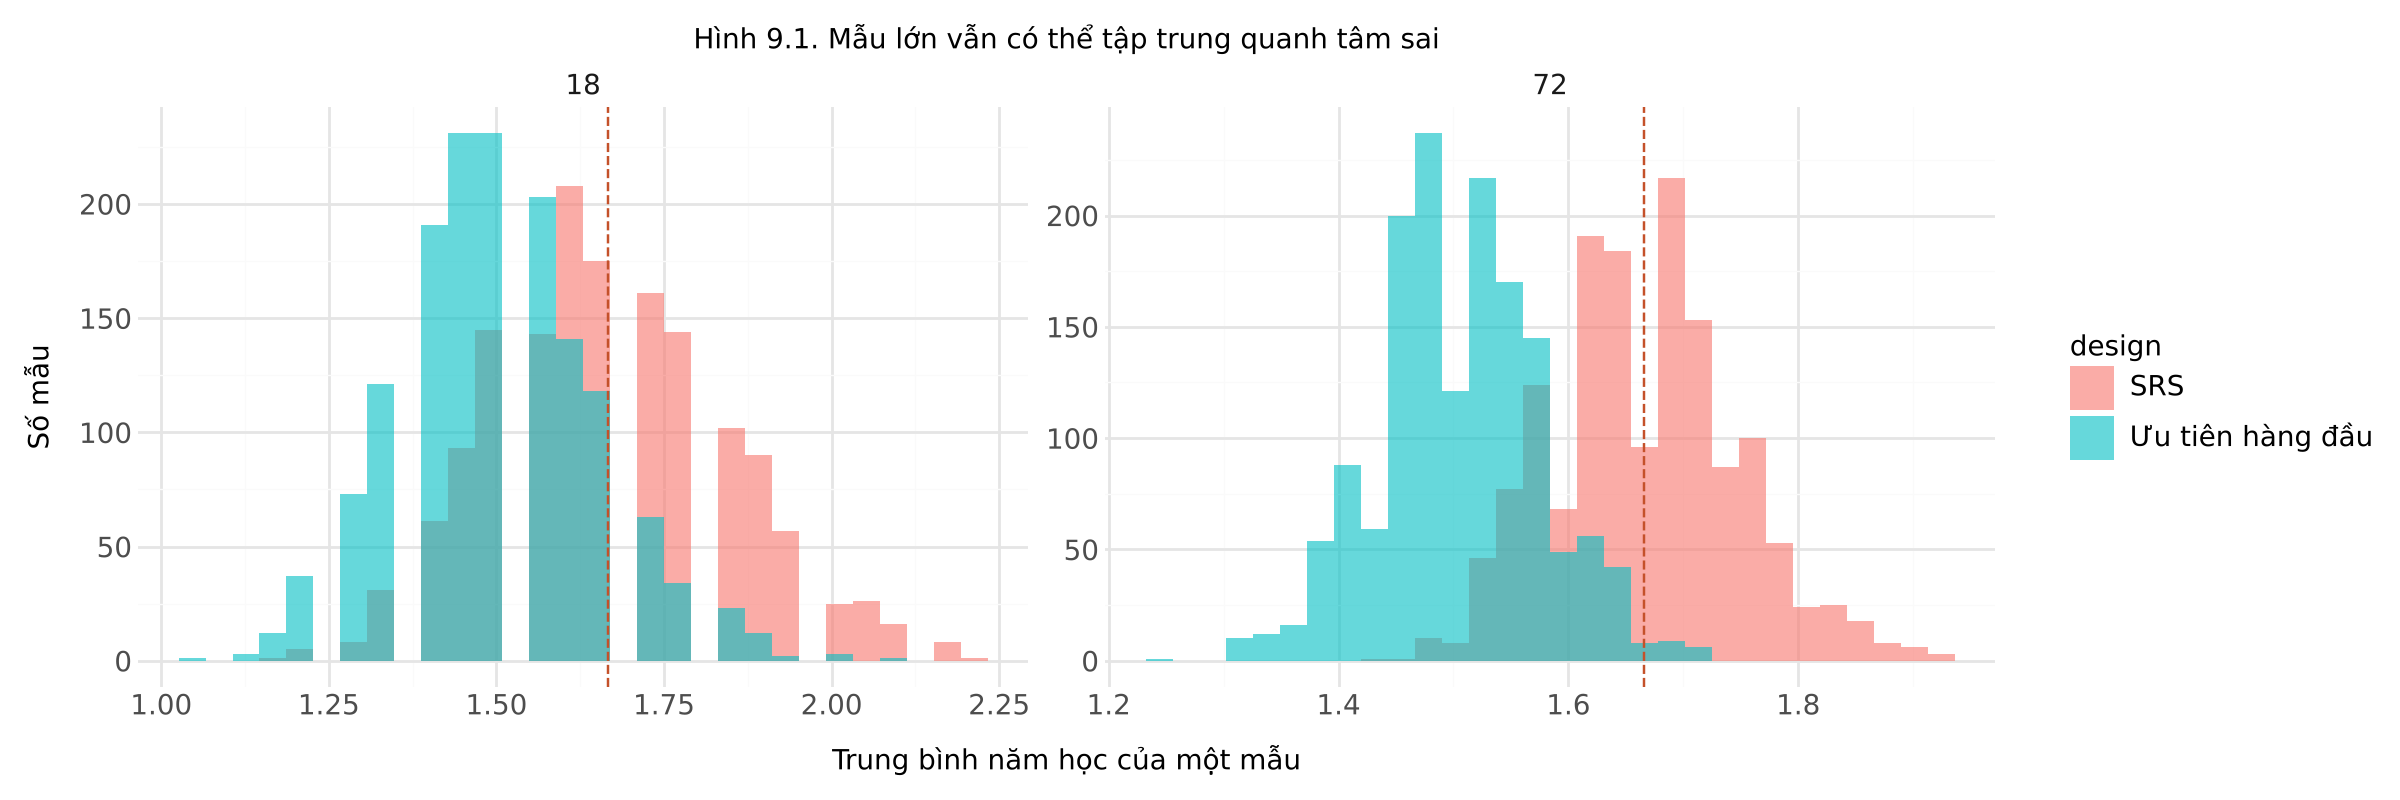

In [4]:
plot_data = sampling_bias.copy()
plot_data['n'] = pd.Categorical(plot_data['n'], categories=list(pd.unique(plot_data['n'])), ordered=True)
p = (ggplot(plot_data, aes(x='mean_year', fill='design'))
     + geom_histogram(bins=30, alpha=0.6, position='identity')
     + geom_vline(xintercept=population_year.mean(), linetype='dashed', color='#C4512A')
     + facet_wrap('~n', scales='free', ncol=3)
     + labs(title='Hình 9.1. Mẫu lớn vẫn có thể tập trung quanh tâm sai', x='Trung bình năm học của một mẫu', y='Số mẫu')
     + theme_minimal()
     + theme(figure_size=(12, max(4, 3.4*int(np.ceil(sampling_bias['n'].nunique()/3)))), text=element_text(size=10)))
display(p)

**Kết quả.** Với SRS, cột `mean` gần 1,666 ở cả hai cỡ mẫu: quy trình không chệch. Với cách ưu tiên hàng đầu, `mean` khoảng 1,50 ở **cả** $n=18$ và $n=72$: độ chệch khoảng $-0{,}17$ năm không giảm. Trong khi đó `std` của cả hai cách đều giảm khoảng một nửa khi $n$ tăng gấp 4 (từ khoảng 0,18 xuống 0,08 với SRS).

Kết luận cho câu hỏi mở đầu: hỏi thêm người ở hàng đầu cho một con số **ổn định hơn**, nhưng ổn định quanh một giá trị sai. Lớp giả lập này chỉ dùng để thấy cơ chế; nó không nói số năm học thật của lớp 527 người.

<a id="muc-2"></a>

## 2. Mỗi điểm trong phân phối mẫu là một thống kê

### Ý tưởng: lặp lại cả quy trình

Hãy tưởng tượng làm đi làm lại **cùng một quy trình**: lấy một mẫu cỡ $n$ từ cùng tổng thể theo cùng cách, rồi tính cùng một thống kê $T$ (ví dụ $\bar x$). Mỗi lần lặp cho **một con số**. Histogram của rất nhiều con số đó là **phân phối mẫu** của $T$.

Khi đọc một phân phối mẫu, ta hỏi ba câu:

1. **Tâm** ở đâu? Nếu tâm trùng với tham số, thống kê không chệch.
2. **Độ phân tán** bao nhiêu? Độ lệch chuẩn của phân phối mẫu được gọi là **sai số chuẩn**, $SE(T)$.
3. **Hình dạng** thế nào? Thường gặp nhất là xấp xỉ chuẩn, nhờ định lý giới hạn trung tâm.

### Ba phân phối dễ nhầm

| Phân phối | Mỗi giá trị là | Tâm | Độ phân tán |
|---|---|---|---|
| Tổng thể | một nhà hàng (một cá thể) | $\mu$ | $\sigma$ |
| Thực nghiệm (dữ liệu của một mẫu) | một nhà hàng trong mẫu | $\bar x$ | $s$ |
| Phân phối mẫu của $\bar X$ | **trung bình** của cả một mẫu | $\mu$ | $SE(\bar X)$ |

Hai dòng đầu nói về cá thể; dòng thứ ba nói về trung bình. Đây là chỗ hay nhầm nhất của buổi học.

### Công thức cho trung bình mẫu

Nếu $X_1,\ldots, X_n$ độc lập, cùng phân phối, có trung bình $\mu$ và phương sai $\sigma^2$ hữu hạn, thì

$$E(\bar X)=\mu,\qquad \mathrm{Var}(\bar X)=\frac{\sigma^2}{n},\qquad SE(\bar X)=\frac{\sigma}{\sqrt n}.$$

Đọc là: trung bình mẫu có tâm đúng bằng trung bình tổng thể; độ phân tán của nó bằng độ phân tán của một cá thể chia cho căn bậc hai của cỡ mẫu. Vì có căn bậc hai, muốn SE giảm một nửa thì $n$ phải tăng **gấp 4**.

Về hình dạng: nếu tổng thể có phân phối chuẩn thì $\bar X$ chuẩn với mọi $n$. Nếu không, CLT cho biết $\bar X$ xấp xỉ chuẩn khi $n$ đủ lớn. "Đủ lớn" tùy vào tổng thể lệch đến đâu: tổng thể gần đối xứng thì vài chục là đủ, tổng thể rất lệch hay có ngoại lai lớn thì cần nhiều hơn. Con số 30 hay được nhắc chỉ là kinh nghiệm, không phải ngưỡng bảo đảm.
<details><summary><b>Vì sao?</b> $E(\bar X)=\mu$ và $\mathrm{Var}(\bar X)=\sigma^2/n$</summary>

*Kỳ vọng.* $\bar X=\frac1n(X_1+\cdots+X_n)$. Kỳ vọng của tổng bằng tổng các kỳ vọng (không cần độc lập), và hằng số $\frac1n$ đưa ra ngoài được:
$$E(\bar X)=\frac1n\big(E(X_1)+\cdots+E(X_n)\big)=\frac1n\cdot n\mu=\mu.$$

*Phương sai.* $\mathrm{Var}(cY)=c^2\mathrm{Var}(Y)$, và với các biến **độc lập**, phương sai của tổng bằng tổng các phương sai:
$$\mathrm{Var}(\bar X)=\frac1{n^2}\big(\mathrm{Var}(X_1)+\cdots+\mathrm{Var}(X_n)\big)=\frac1{n^2}\cdot n\sigma^2=\frac{\sigma^2}n.$$
Lấy căn được $SE(\bar X)=\sigma/\sqrt n$. $\blacksquare$

Bước phương sai cần độc lập. Nếu các quan sát tương quan dương (người cùng nhóm, cùng khu phố), phương sai của $\bar X$ lớn hơn $\sigma^2/n$; đó là lý do mẫu cụm kém chính xác hơn SRS cùng cỡ.

</details>

**Lấy mẫu không hoàn lại.** Khi bốc $n$ người khác nhau từ $N$ người, các lần bốc không hoàn toàn độc lập. Nếu $n$ không quá 10% của $N$, sự phụ thuộc này nhỏ đến mức có thể bỏ qua; slide dùng quy tắc này.
<details><summary><b>Vì sao?</b> hiệu chỉnh tổng thể hữu hạn</summary>

Với SRS không hoàn lại cỡ $n$ từ tổng thể $N$ phần tử có phương sai $\sigma^2=\frac1N\sum_{i=1}^N(x_i-\mu)^2$, có thể chứng minh
$$\mathrm{Var}(\bar X)=\frac{\sigma^2}{n}\cdot\frac{N-n}{N-1}.$$
Thừa số $\frac{N-n}{N-1}$ nhỏ hơn 1: bốc không hoàn lại thì chính xác hơn, và khi $n=N$ (điều tra toàn bộ) thì phương sai bằng 0. Với nhà hàng ở Ví dụ 6–7, $N=5766$, $n=100$: thừa số bằng $\frac{5666}{5765}\approx0{,}983$, căn của nó $\approx0{,}991$. SE chỉ giảm từ 0,890 xuống 0,882, nên bỏ qua hiệu chỉnh là hợp lý. Ô code của Ví dụ 7 in cả hai con số này.

</details>

### Ví dụ 6

Tổng thể gồm 5.766 nhà hàng ở San Francisco; biến quan sát là điểm kiểm tra an toàn thực phẩm (thang 100). Giả sử biết $\mu=87{,}6$ và $\sigma=8{,}9$. Trong phân phối tổng thể, một giá trị ứng với cái gì, và $\sigma=8{,}9$ mô tả điều gì?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

Mỗi giá trị là **điểm của một nhà hàng**. $\mu=87{,}6$ là điểm trung bình của cả 5.766 nhà hàng. $\sigma=8{,}9$ điểm cho biết điểm của từng nhà hàng thường cách 87,6 khoảng chừng 9 điểm: có nhà hàng 95, có nhà hàng 75.

</details>

### Ví dụ 7

Một mẫu ngẫu nhiên cụ thể có $n=100$, $\bar x=86{,}27$, $s=9{,}9$. (1) Phân phối thực nghiệm của mẫu này gồm những giá trị nào? (2) Nếu lặp lại việc lấy mẫu 100 nhà hàng 5.000 lần và ghi lại 5.000 giá trị $\bar x$, phân phối đó có tâm và độ phân tán bao nhiêu? (3) Có nên nói “điểm các nhà hàng chỉ dao động khoảng 0,89” không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.* Phân phối thực nghiệm gồm **100 điểm của 100 nhà hàng** trong mẫu. Tâm $\bar x=86{,}27$, độ phân tán $s=9{,}9$, gần với $\sigma=8{,}9$ của tổng thể.

*Câu 2.* Phân phối mẫu gồm **5.000 giá trị trung bình**. Tâm gần $\mu=87{,}6$. Độ phân tán:
$$SE(\bar X)=\frac{\sigma}{\sqrt n}=\frac{8{,}9}{\sqrt{100}}=0{,}89\text{ điểm}.$$
Hình dạng gần chuẩn nhờ CLT, dù điểm từng nhà hàng lệch trái (nhiều nhà hàng điểm cao, ít nhà hàng điểm thấp).

*Câu 3.* Không. 0,89 là độ dao động của **điểm trung bình 100 nhà hàng** giữa các mẫu. Điểm của từng nhà hàng dao động cỡ 8,9 điểm. Một mẫu có $\bar x=86{,}27$, cách $\mu$ khoảng $1{,}33$ điểm, tức chừng $1{,}5$ lần SE: chuyện đó xảy ra khá thường.

</details>

**Mô phỏng ba phân phối.** Slide không kèm điểm gốc của 5.766 nhà hàng, nên ô dưới tự **dựng một tổng thể giả lập** có đúng $\mu=87{,}6$ và $\sigma=8{,}9$, lệch trái như điểm thật. Các bước:

1. `r_food.beta(10, 1.5, 5766)`: sinh 5.766 số từ phân phối Beta lệch trái;
2. chuẩn hóa rồi kéo về tâm 87,6 và độ lệch chuẩn 8,9;
3. `food_sample`: bốc một mẫu 100 nhà hàng;
4. `means_food`: lặp 5.000 lần việc bốc 100 nhà hàng, mỗi lần lưu một trung bình.

Một mẫu bốc ra từ tổng thể giả lập này không có đúng $\bar x=86{,}27$, $s=9{,}9$ như Ví dụ 7; hai số của ví dụ vẫn được dùng nguyên ở Ví dụ 11.

**Bạn đoán trước:** trong bảng in ra, cột `std` của "5.000 trung bình" xấp xỉ bao nhiêu?

In [5]:
r_food = np.random.default_rng(42)
raw = r_food.beta(10, 1.5, 5766)
food = 87.6 + 8.9*(raw-raw.mean())/raw.std(ddof=0)
assert food.min()>=0 and food.max()<=100
food_sample = r_food.choice(food, 100, replace=False)
means_food = np.array([r_food.choice(food, 100, replace=False).mean() for _ in range(5000)])
three = pd.concat([pd.DataFrame({'value':v,'distribution':k}) for k,v in
    [('Tổng thể mô phỏng',food),('Một mẫu 100',food_sample),('5.000 trung bình',means_food)]])
display(three.groupby('distribution')['value'].agg(['mean','std','count']))
print('SE iid:',8.9/np.sqrt(100),'SE có hiệu chỉnh:',8.9*np.sqrt((5766-100)/(100*(5766-1))))

,mean,std,count
distribution,,,
5.000 trung bình,87.61277,0.87642,5000
Một mẫu 100,87.17950,9.02793,100
Tổng thể mô phỏng,87.60000,8.90077,5766


SE iid: 0.89 SE có hiệu chỉnh: 0.8823251038582807


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(three, aes(...))` lấy bảng `three`; trong `aes`, trục ngang là cột `value`. `geom_histogram(bins=30)` chia trục ngang thành 30 khoảng bằng nhau rồi đếm số dòng của bảng rơi vào mỗi khoảng; chiều cao cột là số đếm. `facet_wrap('~distribution', scales='free')` vẽ mỗi giá trị của `distribution` vào một ô riêng; `scales='free'` cho mỗi ô thang trục riêng, nên so các ô bằng số ghi trên trục, không bằng độ cao trên màn hình.

**Đọc hình.** Đọc số trên trục ngang của từng ô trước khi nhìn hình dạng. Hai ô “Tổng thể mô phỏng” và “Một mẫu 100” trải từ khoảng 50 đến 100 điểm và lệch trái. Ô “5.000 trung bình” chỉ trải trong vài điểm quanh 87,6 và có dạng chuông.

<!-- branch-plot-instructions: end -->

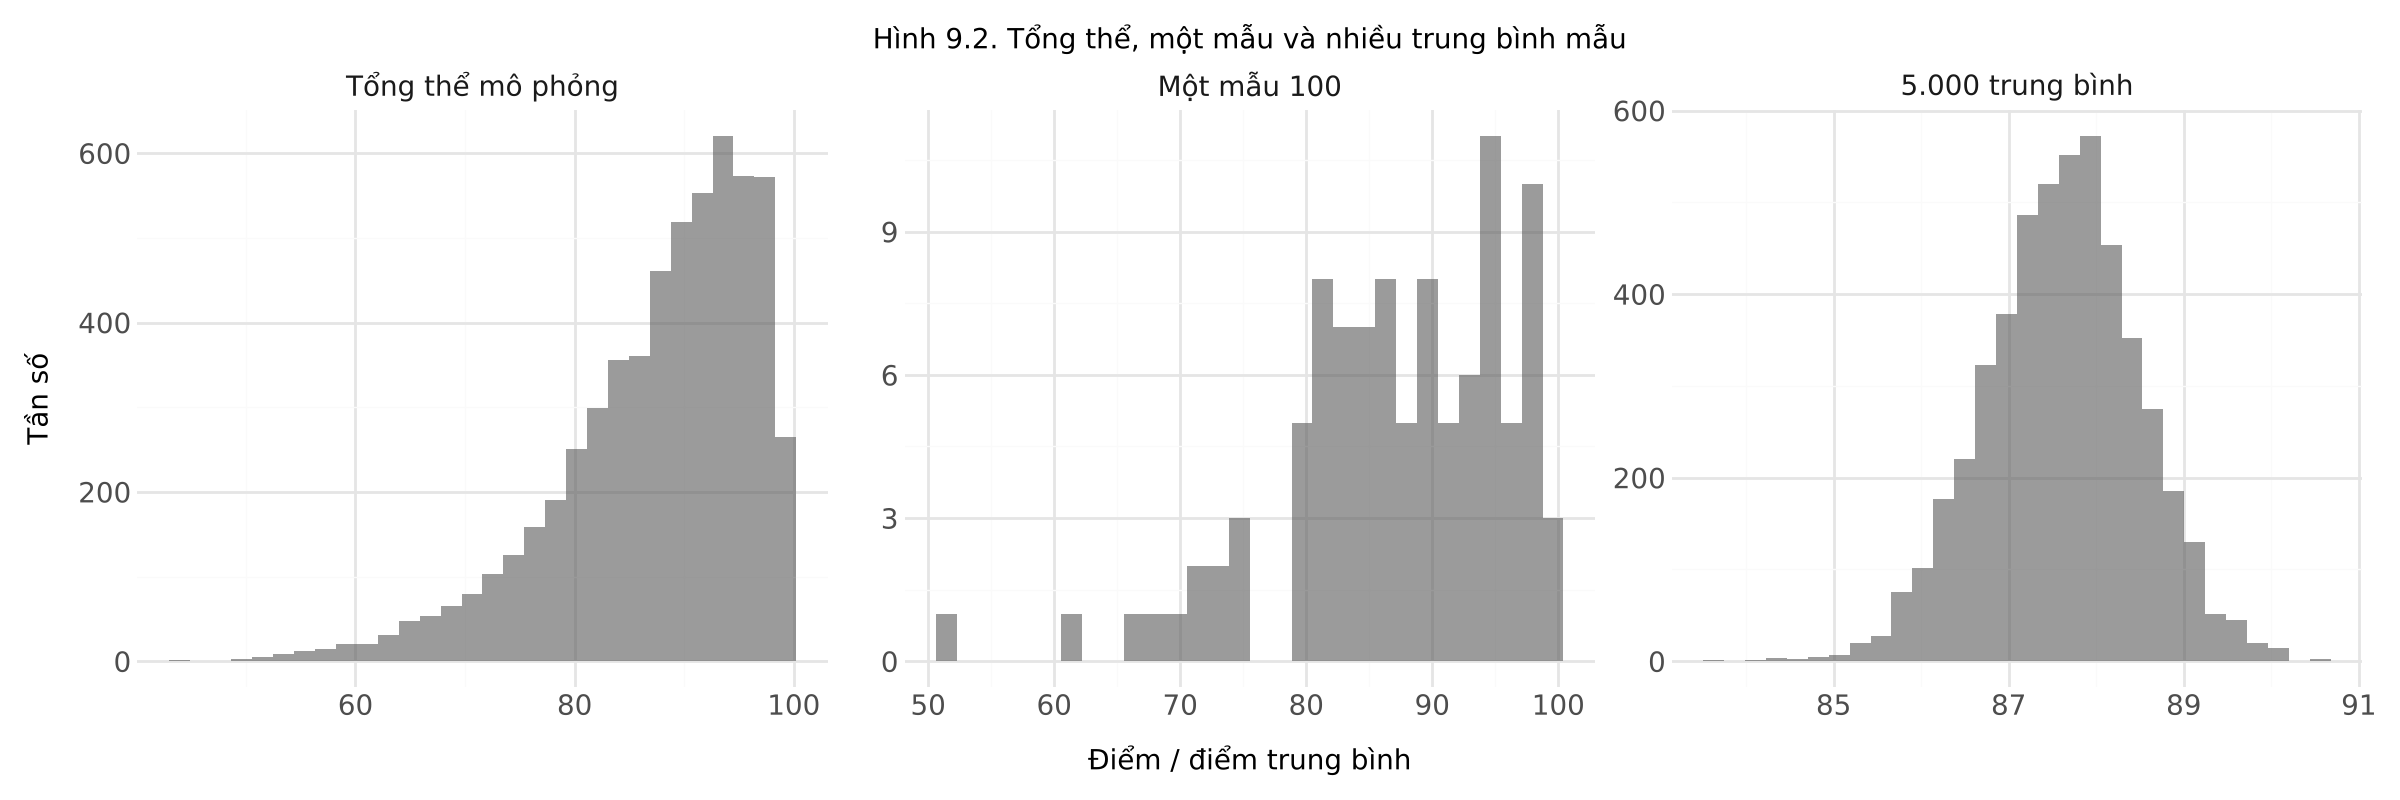

In [6]:
plot_data = three.copy()
plot_data['distribution'] = pd.Categorical(plot_data['distribution'], categories=list(pd.unique(plot_data['distribution'])), ordered=True)
p = (ggplot(plot_data, aes(x='value'))
     + geom_histogram(bins=30, alpha=0.6, position='identity')
     + facet_wrap('~distribution', scales='free', ncol=3)
     + labs(title='Hình 9.2. Tổng thể, một mẫu và nhiều trung bình mẫu', x='Điểm / điểm trung bình', y='Tần số')
     + theme_minimal()
     + theme(figure_size=(12, max(4, 3.4*int(np.ceil(three['distribution'].nunique()/3)))), text=element_text(size=10)))
display(p)

**Kết quả.** Độ lệch chuẩn của 5.000 trung bình khoảng 0,88, khớp với $SE=0{,}89$ (chính xác hơn là 0,882 nếu tính hiệu chỉnh tổng thể hữu hạn). Hai ô đầu có độ lệch chuẩn khoảng 9 vì chúng mô tả **từng nhà hàng**.

Hình còn cho thấy CLT hoạt động: dữ liệu gốc lệch trái rõ, nhưng trung bình của 100 nhà hàng thì gần đối xứng.

### Phân phối mẫu của tỉ lệ

Nhiều câu hỏi đếm "có hay không": ủng hộ hay không, đạt chuẩn hay không. Mã hóa mỗi người thành 1 (có) hoặc 0 (không). Nếu trong mẫu cỡ $n$ có $K$ người mang giá trị 1 thì **tỉ lệ mẫu** là $\hat p=K/n$; đây chính là trung bình của các số 0 và 1.

Với các lần thử Bernoulli$(p)$ độc lập (hoặc lấy không hoàn lại nhưng $n\le10\%$ của $N$):

$$E(\hat p)=p,\qquad SE(\hat p)=\sqrt{\frac{p(1-p)}{n}}.$$

Lý do: $K\sim\operatorname{Binomial}(n, p)$ nên $E(K)=np$ và $\mathrm{Var}(K)=np(1-p)$; chia cho $n$ được $E(\hat p)=p$ và $\mathrm{Var}(\hat p)=np(1-p)/n^2=p(1-p)/n$.

Về hình dạng, $\hat p$ xấp xỉ chuẩn khi số thành công và số thất bại kỳ vọng đều đủ lớn. Slide dùng điều kiện $np\ge10$ và $n(1-p)\ge10$. Khi chưa biết $p$, ta kiểm tra bằng số đếm quan sát: $n\hat p\ge10$ và $n(1-\hat p)\ge10$.

### Ví dụ 8

Giả sử 88% người trưởng thành Hoa Kỳ ủng hộ mở rộng điện mặt trời, tức $p=0{,}88$. Với mẫu ngẫu nhiên $n=1000$, tỉ lệ mẫu $\hat p$ có tâm, sai số chuẩn bao nhiêu? Có dùng được xấp xỉ chuẩn không? Nếu chỉ hỏi 250 người thì SE bằng bao nhiêu?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Tâm:* $E(\hat p)=p=0{,}88$.

*Sai số chuẩn:*
$$SE(\hat p)=\sqrt{\frac{0{,}88\times0{,}12}{1000}}=\sqrt{0{,}0001056}\approx0{,}0103,$$
tức khoảng 1 điểm phần trăm. Phần lớn các mẫu sẽ cho $\hat p$ trong khoảng $0{,}88\pm2\times0{,}0103$, tức từ khoảng 86% đến 90%.

*Điều kiện:* $np=880\ge10$ và $n(1-p)=120\ge10$, nên xấp xỉ chuẩn dùng được.

*Với $n=250$:* $\sqrt{0{,}1056/250}\approx0{,}0206$. Cỡ mẫu giảm 4 lần thì SE tăng gấp đôi.

Ở đây $p=0{,}88$ là giả định của bài toán để tính, không phải số liệu mới.

</details>

Ô dưới mô phỏng 5.000 khảo sát, mỗi khảo sát hỏi `n_prop` người. `rng.binomial(n_prop, 0.88, 5000)` cho số người ủng hộ trong từng khảo sát; chia cho `n_prop` được 5.000 giá trị $\hat p$. So độ lệch chuẩn của chúng với công thức $\sqrt{p(1-p)/n}$.

In [7]:
n_prop = 1000  # Thử đổi: 100, 1000, 4000
proportions = pd.DataFrame({'p_hat': rng.binomial(n_prop, 0.88, 5000)/n_prop})
print('SE lý thuyết:', np.sqrt(0.88*0.12/n_prop), '; SD mô phỏng:', proportions.p_hat.std())

SE lý thuyết: 0.010276186062932104 ; SD mô phỏng: 0.01025762641842391


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(proportions, aes(...))` lấy bảng `proportions`; trong `aes`, trục ngang là cột `p_hat`. `geom_histogram(bins=30)` chia trục ngang thành 30 khoảng bằng nhau rồi đếm số dòng của bảng rơi vào mỗi khoảng; chiều cao cột là số đếm. `geom_vline(xintercept=...)` vẽ đường đứt đoạn tại `0.88`.

**Đọc hình.** Mỗi cột đếm số khảo sát cho ra một mức $\hat p$. Đường đứt đoạn là $p=0{,}88$. Ước lượng bằng mắt khoảng chứa phần lớn các cột rồi so với $0{,}88\pm2\times0{,}0103$.

<!-- branch-plot-instructions: end -->

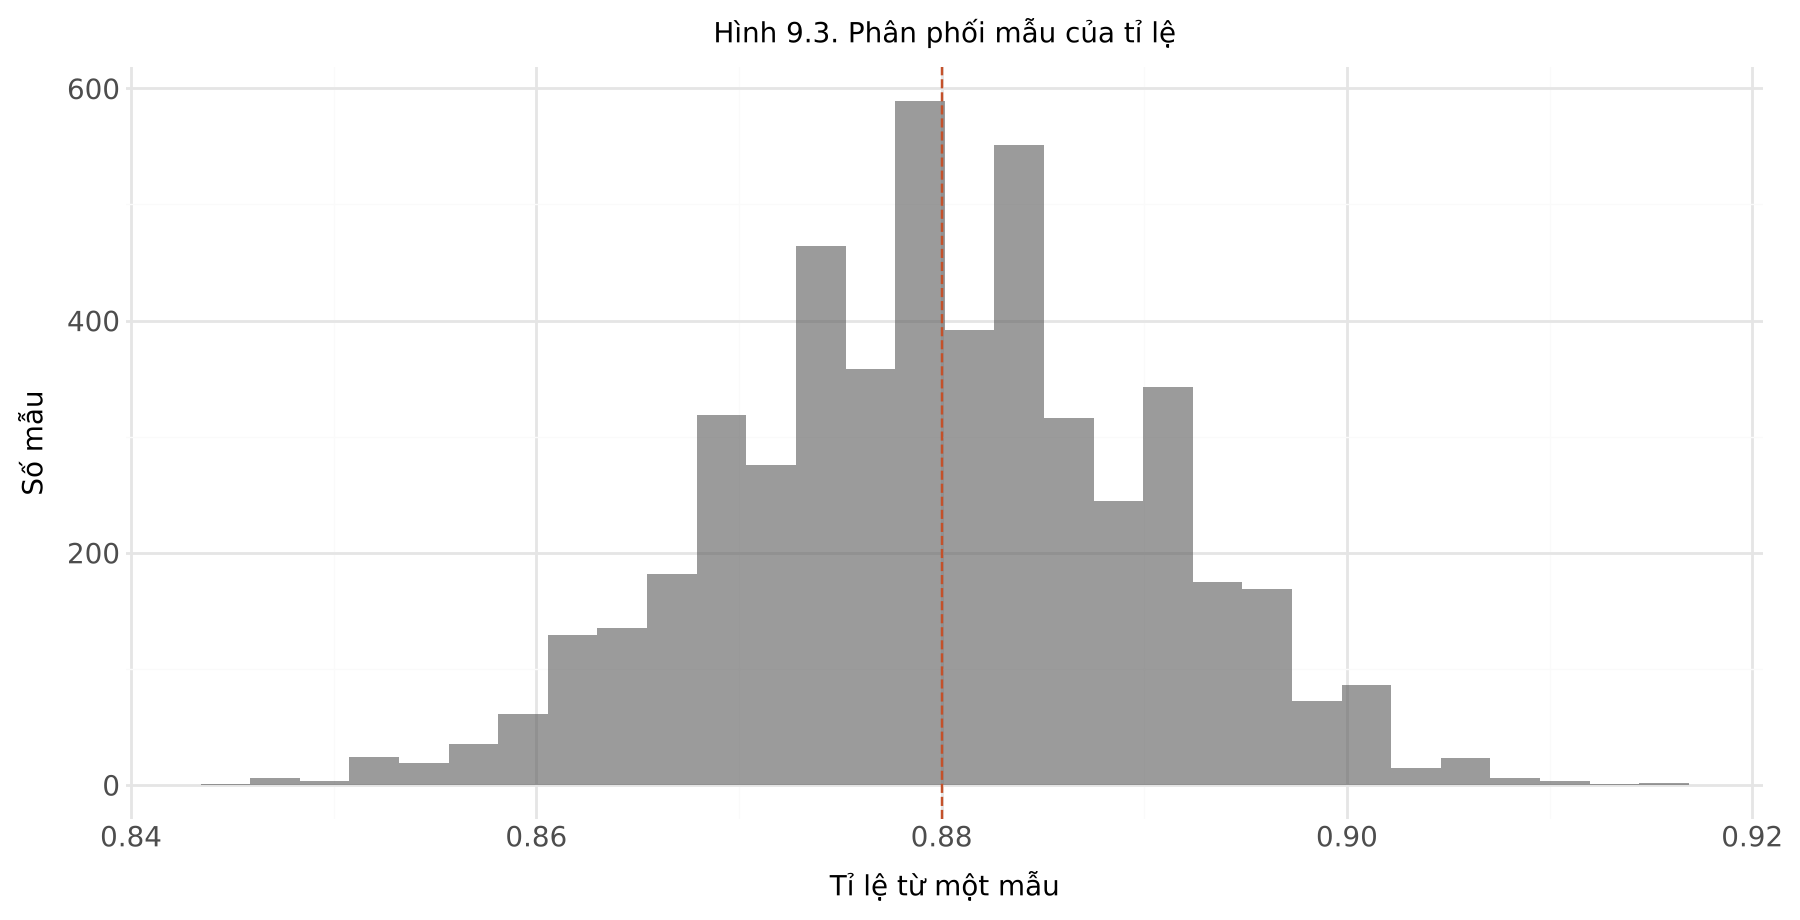

In [8]:
p = (ggplot(proportions, aes(x='p_hat'))
     + geom_histogram(bins=30, alpha=0.6, position='identity')
     + geom_vline(xintercept=0.88, linetype='dashed', color='#C4512A')
     + labs(title='Hình 9.3. Phân phối mẫu của tỉ lệ', x='Tỉ lệ từ một mẫu', y='Số mẫu')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

Hai con số in ra gần như bằng nhau: công thức SE mô tả đúng độ phân tán của các $\hat p$.

**Thử đổi.** Đặt `n_prop = 4000` rồi chạy lại hai ô trên. SE giảm còn khoảng 0,0051, một nửa so với $n=1000$. Lưu ý phân biệt hai con số trong ô: `n_prop` là **số người trong một khảo sát**, quyết định SE; còn 5.000 là **số khảo sát mô phỏng**, chỉ làm histogram mượt hơn và không đổi SE.

<a id="muc-3"></a>

## 3. Ước lượng tốt là tính chất của một quy trình

### Ước lượng điểm và ước lượng khoảng

Gọi $\theta$ là tham số cần biết (ví dụ $\mu$, $p$, $\sigma^2$).

- **Ước lượng điểm** là một quy tắc tính từ mẫu, $\hat\theta=T(X_1,\ldots, X_n)$. Trước khi lấy mẫu, $\hat\theta$ là biến ngẫu nhiên.
- **Giá trị ước lượng** là con số cụ thể $T(x_1,\ldots, x_n)$ tính được từ mẫu đã có.
- **Ước lượng khoảng** gồm hai thống kê $L\le U$ tạo thành khoảng $[L, U]$.

Ước lượng điểm trả lời "ở đâu"; ước lượng khoảng trả lời thêm "chính xác đến mức nào".

Một quy tắc ước lượng tốt hay xấu được đánh giá bằng cách tưởng tượng **dùng nó trên rất nhiều mẫu**. Có ba tiêu chí.

**1. Không chệch.** $\hat\theta$ không chệch nếu $E_\theta(\hat\theta)=\theta$. Độ chệch là $\mathrm{Bias}(\hat\theta)=E_\theta(\hat\theta)-\theta$.
Đọc là: trung bình của ước lượng qua rất nhiều mẫu đúng bằng tham số. Không chệch **không** có nghĩa một mẫu cụ thể cho kết quả đúng.

**2. Vững.** Dãy ước lượng $\hat\theta_n$ là vững nếu với mọi $\varepsilon>0$,
$$P\big(|\hat\theta_n-\theta|>\varepsilon\big)\to0\quad\text{khi }n\to\infty.$$
Đọc là: chọn một mức sai lệch $\varepsilon$ bất kỳ, nhỏ đến đâu cũng được; khi cỡ mẫu tăng mãi, xác suất ước lượng sai quá $\varepsilon$ tiến về 0. Đây chính là luật số lớn ở Tuần 07, áp dụng cho ước lượng.

**3. Hiệu quả.** Trong một **lớp** các ước lượng không chệch của cùng $\theta$, ước lượng có phương sai nhỏ nhất là hiệu quả. Nó dao động ít nhất qua các mẫu. "Hiệu quả" luôn phải nói kèm lớp ước lượng và mô hình đang xét.

### Các ước lượng thường dùng

| Tham số | Ước lượng | Tính chất |
|---|---|---|
| $\mu$ | $\bar X=\frac1n\sum X_i$ | không chệch, vững; hiệu quả khi dữ liệu chuẩn |
| $\sigma^2$ | $S^2=\frac1{n-1}\sum(X_i-\bar X)^2$ | không chệch, vững |
| $p$ | $\hat p=K/n$ | không chệch, vững; hiệu quả trong mô hình Bernoulli |

Mẫu số $n-1$ trong $S^2$ không phải quy ước tùy ý. Các độ lệch $X_i-\bar X$ được đo đến $\bar X$, điểm nằm "giữa" chính dữ liệu, nên trung bình chúng nhỏ hơn một chút so với độ lệch đến $\mu$ thật. Chia $n-1$ thay vì $n$ bù đúng phần hụt đó.
<details><summary><b>Vì sao?</b> $\bar X$ vững, và $E(S^2)=\sigma^2$</summary>

*$\bar X$ vững.* Theo bất đẳng thức Chebyshev (Tuần 07) với $\mathrm{Var}(\bar X)=\sigma^2/n$:
$$P\big(|\bar X-\mu|>\varepsilon\big)\le\frac{\sigma^2}{n\varepsilon^2}\to0\quad\text{khi }n\to\infty.$$
Tổng quát hơn: một ước lượng không chệch có phương sai tiến về 0 thì vững.

*$S^2$ không chệch.* Viết $X_i-\bar X=(X_i-\mu)-(\bar X-\mu)$ rồi khai triển:
$$\sum_{i=1}^n(X_i-\bar X)^2=\sum_{i=1}^n(X_i-\mu)^2-2(\bar X-\mu)\sum_{i=1}^n(X_i-\mu)+n(\bar X-\mu)^2.$$
Vì $\sum(X_i-\mu)=n(\bar X-\mu)$, hai số hạng cuối gộp lại thành $-n(\bar X-\mu)^2$. Lấy kỳ vọng:
$$E\Big[\sum(X_i-\bar X)^2\Big]=n\sigma^2-n\,\mathrm{Var}(\bar X)=n\sigma^2-\sigma^2=(n-1)\sigma^2.$$
Chia cho $n-1$ được $E(S^2)=\sigma^2$. Nếu chia cho $n$, kỳ vọng là $\frac{n-1}{n}\sigma^2$, luôn nhỏ hơn $\sigma^2$. $\blacksquare$

Ghi chú: $S^2$ không chệch nhưng $S=\sqrt{S^2}$ hơi chệch xuống cho $\sigma$. Với $n$ vừa phải, độ chệch này rất nhỏ.

</details>

### Ví dụ 9

Số ngày từ lúc điều trị đến khi khỏi của 11 bệnh nhân: 4, 4, 3, 8, 5, 6, 7, 12, 5, 3, 8. Tính giá trị ước lượng điểm cho trung bình $\mu$ và phương sai $\sigma^2$ của thời gian khỏi bệnh.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Trung bình mẫu.* Tổng các giá trị là $4+4+3+8+5+6+7+12+5+3+8=65$, nên
$$\bar x=\frac{65}{11}\approx5{,}909\text{ ngày}.$$

*Phương sai mẫu.* Dùng công thức tính nhanh $\sum(x_i-\bar x)^2=\sum x_i^2-\frac{(\sum x_i)^2}{n}$. Ta có $\sum x_i^2=16+16+9+64+25+36+49+144+25+9+64=457$, nên
$$\sum(x_i-\bar x)^2=457-\frac{65^2}{11}=457-384{,}09\approx72{,}91,\qquad s^2=\frac{72{,}91}{10}\approx7{,}291\text{ ngày}^2.$$
Độ lệch chuẩn mẫu $s=\sqrt{7{,}291}\approx2{,}70$ ngày.

Đây là hai **giá trị ước lượng** của $\mu$ và $\sigma^2$ cho nhóm bệnh nhân tương tự. Chúng chỉ mô tả thời gian khỏi; muốn biết phương pháp điều trị có tác dụng hay không thì cần một nhóm so sánh (Tuần 12–13).

</details>

Ô dưới làm hai việc.

1. Kiểm tra lại Ví dụ 9. `recovery.var(ddof=1)` chia cho $n-1$; `ddof` là số "bậc tự do bị mất", mặc định bằng 0 (chia $n$).
2. Thí nghiệm so sánh ước lượng. Sinh 4.000 mẫu, mỗi mẫu 20 quan sát từ $\mathcal N(10,\ 2^2)$, tức $\mu=10$, $\sigma^2=4$. Với mỗi mẫu tính:
   - hai ước lượng của $\mu$: trung bình mẫu và **chỉ lấy quan sát đầu tiên**;
   - hai ước lượng của $\sigma^2$: chia $n$ và chia $n-1$.

**Bạn đoán trước:** hai ước lượng của $\mu$ có cùng kỳ vọng không? Cái nào có phương sai nhỏ hơn, và nhỏ hơn khoảng bao nhiêu lần? Ước lượng phương sai nào có trung bình gần 4 hơn?

In [9]:
recovery = np.array([4,4,3,8,5,6,7,12,5,3,8])
print('Trung bình:',recovery.mean(),'ngày; phương sai:',recovery.var(ddof=1),'ngày²')
normal_samples = rng.normal(10, 2, size=(4000, 20))
estimates = pd.DataFrame({'Trung bình':normal_samples.mean(axis=1),
                          'Quan sát đầu':normal_samples[:,0]})
display(estimates.agg(['mean','var']))
print('Phương sai chia n:',normal_samples.var(axis=1).mean(),
      '; chia n-1:',normal_samples.var(axis=1,ddof=1).mean(),'; thật:',4)

Trung bình: 5.909090909090909 ngày; phương sai: 7.290909090909091 ngày²


,Trung bình,Quan sát đầu
mean,9.99824,9.97595
var,0.20119,3.90995


Phương sai chia n: 3.7818662165988055 ; chia n-1: 3.9809118069461107 ; thật: 4


**Đọc kết quả.**

- Hàng `mean`: cả hai ước lượng của $\mu$ đều cho trung bình gần 10. Cả hai **không chệch**.
- Hàng `var`: quan sát đầu có phương sai gần $\sigma^2=4$; trung bình mẫu có phương sai gần $4/20=0{,}2$, nhỏ hơn 20 lần. Trung bình mẫu **hiệu quả hơn**: nó dùng cả 20 quan sát, còn "quan sát đầu" bỏ phí 19 cái.
- Dòng cuối: chia $n$ cho trung bình khoảng 3,8, đúng bằng $\frac{19}{20}\times4$; chia $n-1$ cho khoảng 4,0. Đây là độ chệch mà khối **Vì sao?** ở trên đã tính.

"Quan sát đầu" không chệch nhưng **không vững**: thêm dữ liệu không làm nó tốt lên vì nó bỏ qua dữ liệu mới. Ví dụ này cho thấy không chệch chưa đủ để gọi là ước lượng tốt.

<a id="muc-4"></a>

## 4. Khoảng tin cậy cho trung bình

### Vì sao cần khoảng?

Một ước lượng điểm như $\bar x=86{,}27$ chưa cho biết nếu lấy mẫu khác thì con số đổi bao nhiêu. **Khoảng tin cậy** đưa ra một khoảng giá trị cho tham số, kèm một **mức tin cậy** (thường 90%, 95%, 99%) nói lên quy trình lập khoảng đáng tin đến đâu.

### Mức tin cậy 95% nghĩa là gì?

Tưởng tượng lặp lại nhiều lần: (1) lấy một mẫu ngẫu nhiên; (2) lập khoảng 95% bằng cùng một công thức; (3) ghi lại khoảng đó. Sau rất nhiều lần, **khoảng 95% số khoảng chứa tham số**.

Ba ý theo sau định nghĩa này:

- Tham số $\mu$ đứng yên. Thứ thay đổi qua các mẫu là **hai đầu mút** của khoảng.
- Sau khi đã tính ra một khoảng cụ thể, ví dụ $[84{,}33;\ 88{,}21]$, thì $\mu$ hoặc nằm trong, hoặc không; không còn gì ngẫu nhiên. "95%" là độ tin cậy của **cách làm**, nên ta nói "tin cậy 95%", không nói "xác suất 95% $\mu$ nằm trong khoảng này".
- Khoảng tin cậy cho $\mu$ nói về **trung bình tổng thể**, không phải khoảng chứa 95% số cá thể.

### Rút ra công thức khi biết $\sigma$

Nếu tổng thể chuẩn và biết $\sigma$, thì $\bar X\sim\mathcal N(\mu,\ \sigma^2/n)$, nên
$$Z=\frac{\bar X-\mu}{\sigma/\sqrt n}\sim\mathcal N(0,1).$$
Đọc là: lấy trung bình mẫu trừ tâm rồi chia cho sai số chuẩn thì được biến chuẩn tắc. Gọi $z_{\alpha/2}$ là số thỏa $P(Z\le z_{\alpha/2})=1-\alpha/2$. Khi đó $P(-z_{\alpha/2}\le Z\le z_{\alpha/2})=1-\alpha$. Giải bất đẳng thức để $\mu$ đứng giữa:
$$-z_{\alpha/2}\le\frac{\bar X-\mu}{\sigma/\sqrt n}\le z_{\alpha/2}
\iff
\bar X-z_{\alpha/2}\frac{\sigma}{\sqrt n}\le\mu\le\bar X+z_{\alpha/2}\frac{\sigma}{\sqrt n}.$$
Hai bất đẳng thức tương đương nên có cùng xác suất $1-\alpha$. Thay $\bar X$ bằng giá trị quan sát $\bar x$ được khoảng tin cậy $100(1-\alpha)\%$:
$$\Big[\bar x-z_{\alpha/2}\frac{\sigma}{\sqrt n},\ \ \bar x+z_{\alpha/2}\frac{\sigma}{\sqrt n}\Big].$$

| Mức tin cậy $1-\alpha$ | $\alpha/2$ | $z_{\alpha/2}$ |
|---|---|---|
| 90% | 0,05 | 1,645 |
| 95% | 0,025 | 1,960 |
| 99% | 0,005 | 2,576 |

Trong Python: `stats.norm.ppf(1 - alpha/2)`; `ppf` là hàm ngược của hàm phân phối tích lũy.

### Câu hỏi diễn giải

Từ một mẫu ngẫu nhiên, ta được khoảng tin cậy 95% cho điểm an toàn thực phẩm trung bình của nhà hàng là $[84{,}3;\ 88{,}2]$ điểm. Phát biểu nào phù hợp?

A. 95% nhà hàng có điểm từ 84,3 đến 88,2.

B. Điểm trung bình mẫu có xác suất 95% nằm trong khoảng trên.

C. Ta tin cậy 95% rằng điểm trung bình của tổng thể nhà hàng nằm từ 84,3 đến 88,2.

D. Trung bình tổng thể thay đổi ngẫu nhiên sau mỗi lần lấy mẫu.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

**Đáp án C.** Xét từng phương án:

- **A sai** vì khoảng nói về **trung bình**, không về từng nhà hàng. Điểm từng nhà hàng rải rộng hơn nhiều: $\sigma\approx8{,}9$ trong khi khoảng chỉ rộng khoảng 4 điểm.
- **B sai** vì trung bình mẫu là tâm của khoảng, nó chắc chắn nằm trong khoảng; khoảng được lập để nói về $\mu$, không về $\bar x$.
- **C đúng.** "Tin cậy 95%" nghĩa là quy trình lập khoảng này đúng trong khoảng 95% số lần dùng.
- **D sai** vì $\mu$ là tham số cố định. Thứ thay đổi theo mẫu là $\bar x$ và hai đầu mút.

Phạm vi kết luận ("tổng thể nhà hàng" nào, năm nào) do thiết kế lấy mẫu quyết định.

</details>

**Thí nghiệm 100 khoảng tin cậy.** Ô dưới giả định đã biết $\mu=87{,}6$, $\sigma=8{,}9$ và lặp 100 lần việc lấy mẫu $n$ nhà hàng. Thay vì bốc từng nhà hàng, ô code sinh thẳng 100 giá trị $\bar x$ từ $\mathcal N(87{,}6;\ (8{,}9/\sqrt n)^2)$, vì đó chính là phân phối mẫu của $\bar X$. Với mỗi $\bar x$, lập khoảng $\bar x\pm z^*\sigma/\sqrt n$ rồi kiểm tra khoảng có chứa 87,6 không.

- `stats.norm.ppf((1+level)/2)`: với `level = 0.95` thì $(1+0{,}95)/2=0{,}975$, cho $z^*\approx1{,}96$.
- `margin`: biên sai số, giống nhau cho mọi khoảng vì $\sigma$ đã biết.

**Bạn đoán trước:** trong 100 khoảng, có đúng 95 khoảng chứa $\mu$ không?

In [10]:
# 100 mẫu độc lập từ mô hình chuẩn biết sigma; không phải hồ sơ nhà hàng.
n_ci = 100  # Thử đổi: 25, 100, 400
level = 0.95  # Thử đổi: 0.90, 0.99
sim_mean = rng.normal(87.6, 8.9/np.sqrt(n_ci), 100)
margin = stats.norm.ppf((1+level)/2)*8.9/np.sqrt(n_ci)
intervals = pd.DataFrame({'row':np.arange(1,101),'lower':sim_mean-margin,'end':sim_mean+margin})
intervals['cover'] = np.where((intervals.lower<=87.6)&(intervals.end>=87.6),'Chứa μ','Không chứa μ')
print(intervals.cover.value_counts())

cover
Chứa μ          98
Không chứa μ     2
Name: count, dtype: int64


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(intervals, aes(...))` lấy bảng `intervals`; trong `aes`, trục ngang là cột `lower`, trục đứng là cột `row`. `color='cover'` cho mỗi giá trị của cột `cover` một màu riêng. `geom_segment(aes(xend='end', yend='row'))` vẽ mỗi dòng thành một đoạn ngang từ `x` đến `end`, đặt ở độ cao `row`. `geom_vline(xintercept=...)` vẽ đường đứt đoạn tại `87.6`.

**Đọc hình.** Mỗi đoạn ngang là một khoảng tin cậy từ một mẫu; đường đứng là $\mu=87{,}6$, không bao giờ dịch chuyển. Tìm các đoạn khác màu: chúng nằm hẳn sang một bên của đường đứng. Mọi đoạn dài bằng nhau vì $\sigma$ đã biết.

<!-- branch-plot-instructions: end -->

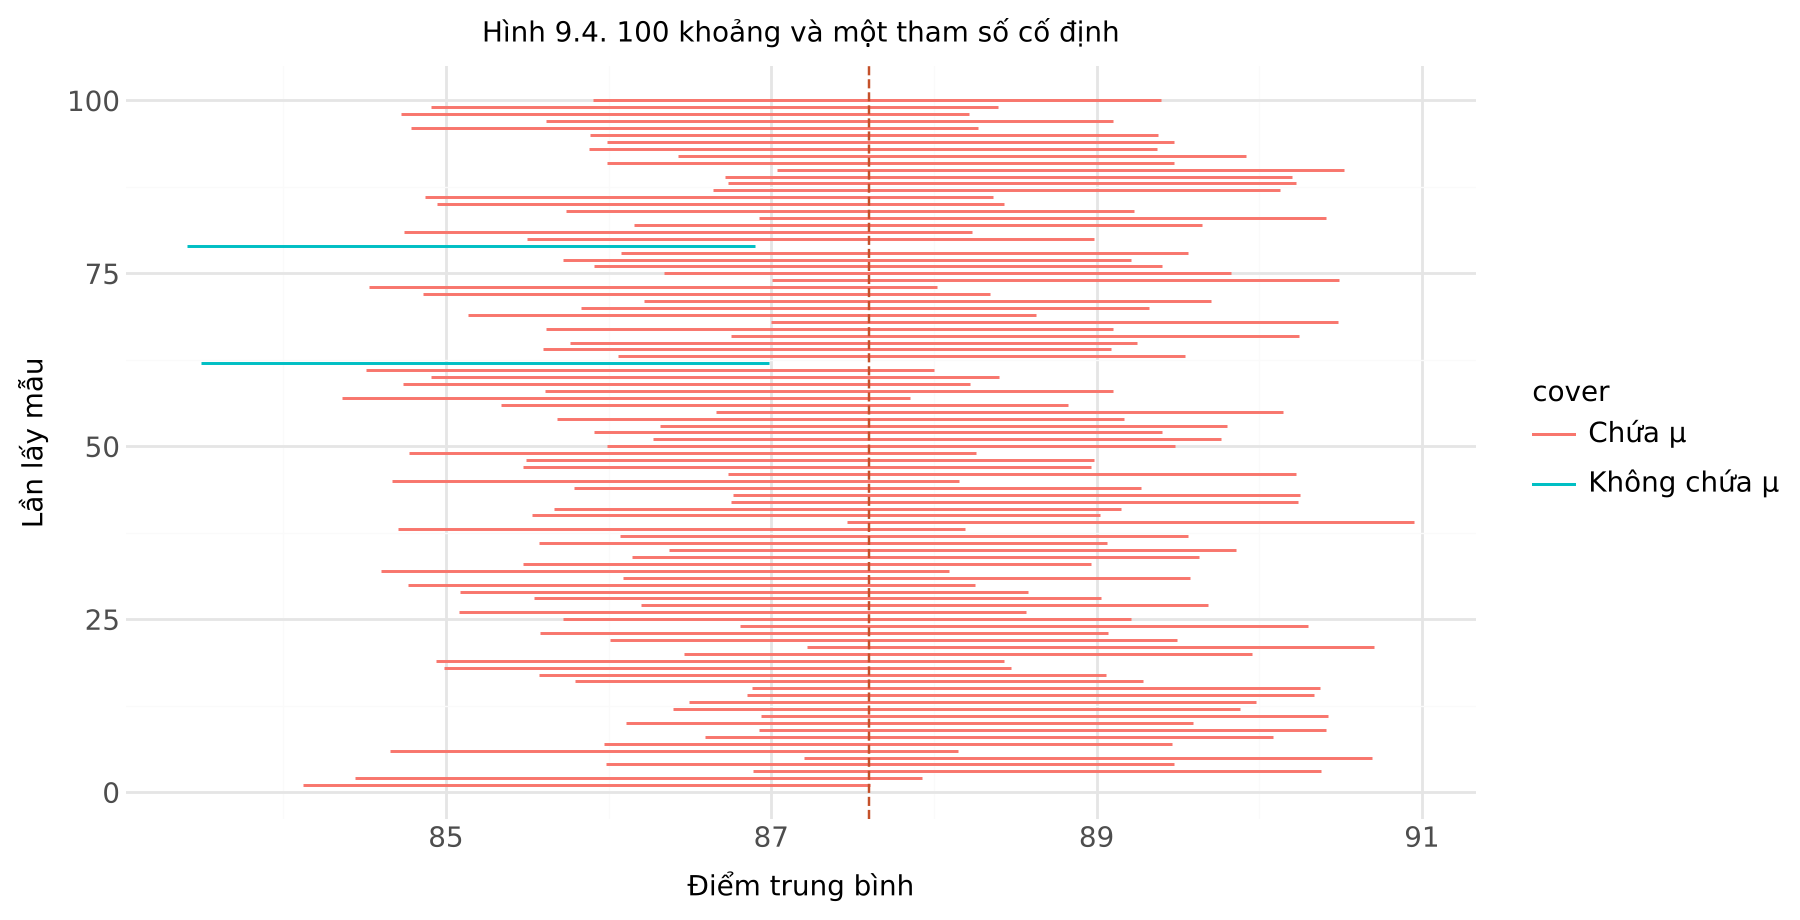

In [11]:
p = (ggplot(intervals, aes(x='lower', y='row', color='cover'))
     + geom_segment(aes(xend='end', yend='row'), size=0.6)
     + geom_vline(xintercept=87.6, linetype='dashed', color='#C4512A')
     + labs(title='Hình 9.4. 100 khoảng và một tham số cố định', x='Điểm trung bình', y='Lần lấy mẫu')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

Lần chạy này có 98 khoảng chứa $\mu$. Số này dao động quanh 95: số khoảng chứa $\mu$ trong 100 lần là biến ngẫu nhiên $\operatorname{Binomial}(100;\ 0{,}95)$, có độ lệch chuẩn $\sqrt{100\times0{,}95\times0{,}05}\approx2{,}2$. Được 93 hay 98 đều bình thường.

**Thử đổi.** (1) `level = 0.99`: các đoạn dài ra và gần như mọi khoảng đều chứa $\mu$. (2) `level = 0.90`: đoạn ngắn lại và khoảng 10 khoảng trượt. (3) `n_ci = 400`: đoạn ngắn còn một nửa so với `n_ci = 100`, nhưng tỉ lệ chứa $\mu$ vẫn quanh mức đã chọn. Cỡ mẫu quyết định **độ rộng**; mức tin cậy quyết định **tỉ lệ trúng**.

### Ba trường hợp lập khoảng cho trung bình

Trong thực tế hiếm khi biết $\sigma$. Slide chia ba trường hợp:

| Trường hợp | Sai số chuẩn | Giá trị tới hạn | Khoảng | Điều kiện |
|---|---|---|---|---|
| 1. Biết $\sigma$ | $\sigma/\sqrt n$ | $z_{\alpha/2}$ | $\bar x\pm z_{\alpha/2}\,\sigma/\sqrt n$ | tổng thể chuẩn (hoặc $n$ lớn) |
| 2. Chưa biết $\sigma$, $n$ lớn | $s/\sqrt n$ | $z_{\alpha/2}$ (xấp xỉ) | $\bar x\pm z_{\alpha/2}\, s/\sqrt n$ | tổng thể bất kỳ, nhờ CLT |
| 3. Chưa biết $\sigma$, tổng thể chuẩn | $s/\sqrt n$ | $t_{\alpha/2,\, n-1}$ | $\bar x\pm t_{\alpha/2,\, n-1}\, s/\sqrt n$ | tổng thể chuẩn, dùng được cả khi $n$ nhỏ |

**Trường hợp 2.** Khi $n$ lớn, CLT cho $\bar X$ xấp xỉ chuẩn, và $s$ gần $\sigma$, nên thay $\sigma$ bằng $s$ vẫn được khoảng có mức tin cậy xấp xỉ $1-\alpha$.

**Trường hợp 3.** Khi thay $\sigma$ bằng $S$, đại lượng
$$T=\frac{\bar X-\mu}{S/\sqrt n}$$
không còn chuẩn tắc nữa mà có **phân phối $t$ với $n-1$ bậc tự do** (nếu tổng thể chuẩn). $S$ cũng dao động theo mẫu, thêm một nguồn bất định, nên phân phối $t$ có đuôi dày hơn và $t^*$ lớn hơn $z^*$: khoảng $t$ rộng hơn khoảng $z$.

| $n$ | 6 | 16 | 31 | 101 | 1001 |
|---|---|---|---|---|---|
| $t_{0{,}025,\, n-1}$ | 2,571 | 2,131 | 2,042 | 1,984 | 1,962 |

Khi $n$ tăng, $t^*$ tiến về 1,960 và hai cách cho kết quả gần như nhau.

**Khi nào tin được khoảng $t$ với mẫu nhỏ?** Vẽ dữ liệu trước. Nếu tổng thể chuẩn, khoảng $t$ đúng chính xác. Nếu lệch vừa phải, nó vẫn khá ổn. Nếu lệch mạnh hoặc có ngoại lai lớn, khoảng $t$ với mẫu nhỏ có thể sai đáng kể.

### Độ rộng và biên sai số

Đại lượng $E=z_{\alpha/2}\,\sigma/\sqrt n$ là **biên sai số** (nửa độ rộng); $2E$ là **độ rộng**. Từ công thức đọc được ba quy luật:

1. Mức tin cậy cao hơn → $z^*$ lớn hơn → khoảng rộng hơn.
2. Cỡ mẫu lớn hơn → $\sqrt n$ lớn hơn → khoảng hẹp hơn.
3. Dữ liệu phân tán hơn ($\sigma$ lớn) → khoảng rộng hơn.

Biên sai số là độ rộng của **quy trình**: khoảng 95% số mẫu có $|\bar x-\mu|\le E$. Với mẫu đang có, ta không biết nó thuộc 95% hay 5% còn lại.

Bốn ví dụ dưới đây ứng với ba trường hợp. Trước khi giải, xác định: đã biết $\sigma$ chưa? $n$ lớn hay nhỏ? Có giả thiết chuẩn không?

### Ví dụ 10

Một mẫu ngẫu nhiên gồm 50 sinh viên có chiều cao trung bình 160 cm. Giả sử chiều cao có phân phối chuẩn và độ lệch chuẩn tổng thể đã biết $\sigma=5$ cm. Lập khoảng tin cậy 95% cho chiều cao trung bình của tổng thể.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Chọn công thức.* Biết $\sigma$ và tổng thể chuẩn: **trường hợp 1**, dùng $z$.

*Bước 1.* Mức 95% nên $\alpha=0{,}05$, $z_{0{,}025}\approx1{,}96$.

*Bước 2.* Sai số chuẩn: $\sigma/\sqrt n=5/\sqrt{50}\approx0{,}7071$ cm.

*Bước 3.* Biên sai số: $E=1{,}96\times0{,}7071\approx1{,}39$ cm.

*Bước 4.* Khoảng: $160\pm1{,}39=[158{,}61;\ 161{,}39]$ cm.

*Diễn giải.* Ta tin cậy 95% rằng chiều cao trung bình của tổng thể sinh viên được nghiên cứu nằm trong khoảng từ 158,61 đến 161,39 cm.

</details>

### Ví dụ 11

Năm 2016, San Francisco ghi nhận điểm kiểm tra an toàn thực phẩm của các nhà hàng. Trên một mẫu ngẫu nhiên 100 nhà hàng, $\bar x=86{,}27$ và $s=9{,}9$. Tìm khoảng tin cậy 95% cho điểm trung bình.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Chọn công thức.* Chưa biết $\sigma$, $n=100$ lớn: **trường hợp 2**, khoảng $z$ xấp xỉ. Điểm nhà hàng lệch trái nhưng $n=100$ đủ để CLT có tác dụng (xem Hình 9.2).

*Bước 1.* $SE=s/\sqrt n=9{,}9/10=0{,}99$ điểm.

*Bước 2.* $E=1{,}96\times0{,}99\approx1{,}94$ điểm.

*Bước 3.* Khoảng: $86{,}27\pm1{,}94=[84{,}33;\ 88{,}21]$ điểm.

*Diễn giải.* Ta tin cậy xấp xỉ 95% rằng điểm an toàn thực phẩm trung bình của các nhà hàng thuộc phạm vi nghiên cứu nằm trong khoảng 84,33–88,21 điểm. Chữ "xấp xỉ" vì đã thay $\sigma$ bằng $s$ và dùng CLT.

Khoảng này chứa 87,6, giá trị $\mu$ giả định ở Ví dụ 6. Đây là một trong khoảng 95% trường hợp trúng.

</details>

### Ví dụ 12

Một mẫu ngẫu nhiên 50 xe Porsche Boxster có số dặm trung bình 45.679,4 miles và độ lệch chuẩn 26.641,675 miles. Tìm khoảng tin cậy 90% cho số dặm trung bình của tổng thể các xe này.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Chọn công thức.* Chưa biết $\sigma$, $n=50$: **trường hợp 2**, khoảng $z$ xấp xỉ.

*Bước 1.* Mức 90% nên $\alpha=0{,}10$, $\alpha/2=0{,}05$, $z_{0{,}05}\approx1{,}645$.

*Bước 2.* $SE=26\,641{,}675/\sqrt{50}\approx26\,641{,}675/7{,}0711\approx3\,767{,}70$ miles.

*Bước 3.* $E=1{,}645\times3\,767{,}70\approx6\,197$ miles.

*Bước 4.* Khoảng: $45\,679{,}4\pm6\,197\approx[39\,482;\ 51\,877]$ miles.

*Nhận xét.* $s$ gần bằng 58% trung bình; số dặm không thể âm, nên dữ liệu nhiều khả năng lệch phải. Với $n=50$, mức 90% chỉ nên hiểu là xấp xỉ; nếu có dữ liệu gốc, nên vẽ histogram trước khi tin con số này.

</details>

### Ví dụ 13

Chiều cao (cm) của 16 nữ sinh viên được chọn ngẫu nhiên: 162, 155, 170, 165, 160, 165, 158, 164, 168, 150, 165, 167, 164, 159, 152, 154. Giả sử chiều cao nữ sinh viên có phân phối chuẩn. Tìm khoảng tin cậy 95% cho chiều cao trung bình.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Chọn công thức.* Chưa biết $\sigma$, $n=16$ nhỏ, có giả thiết chuẩn: **trường hợp 3**, dùng $t$.

*Bước 1: trung bình.* Tổng 16 số là 2578, nên $\bar x=2578/16=161{,}125$ cm.

*Bước 2: độ lệch chuẩn.* $\sum(x_i-\bar x)^2=533{,}75$, nên $s^2=533{,}75/15\approx35{,}58$ và $s\approx5{,}965$ cm.

*Bước 3: sai số chuẩn.* $s/\sqrt{16}=5{,}965/4\approx1{,}491$ cm.

*Bước 4: giá trị tới hạn.* Bậc tự do $df=n-1=15$; $t_{0{,}025,\,15}\approx2{,}131$ (lớn hơn 1,96).

*Bước 5: khoảng.* $161{,}125\pm2{,}131\times1{,}491=161{,}125\pm3{,}18=[157{,}95;\ 164{,}30]$ cm.

*Diễn giải.* Ta tin cậy 95% rằng chiều cao trung bình của nữ sinh viên thuộc tổng thể nghiên cứu nằm trong khoảng 157,95–164,30 cm. Nếu dùng nhầm 1,96, biên sai số sẽ là 2,92 cm thay vì 3,18 cm: khoảng hẹp hơn thực tế và mức tin cậy thật thấp hơn 95%.

</details>

Ô dưới kiểm tra bốn đáp án. Ba ví dụ đầu dùng cùng công thức $z$ trong vòng `for`; Ví dụ 13 dùng `stats.t.interval(0.95, df, loc=..., scale=SE)`, hàm trả về thẳng hai đầu mút của khoảng $t$.

In [12]:
cases_mean = [('VD10',50,160,5,0.95),('VD11',100,86.27,9.9,0.95),
              ('VD12',50,45679.4,26641.675,0.90)]
results = []
for label,n,mean,sd,confidence in cases_mean:
    z = stats.norm.ppf((1+confidence)/2)
    se = sd/np.sqrt(n)
    results.append([label,se,mean-z*se,mean+z*se])
heights = np.array([162,155,170,165,160,165,158,164,168,150,165,167,164,159,152,154])
se_h = heights.std(ddof=1)/np.sqrt(len(heights))
ci_h = stats.t.interval(0.95,len(heights)-1,loc=heights.mean(),scale=se_h)
results.append(['VD13',se_h,*ci_h])
display(pd.DataFrame(results,columns=['Ví dụ','SE','Cận dưới','Cận trên']))
assert np.isclose(heights.mean(),161.125)

,Ví dụ,SE,Cận dưới,Cận trên
0,VD10,0.70711,158.61410,161.38590
1,VD11,0.99000,84.32964,88.21036
2,VD12,3767.70181,39482.08201,51876.71799
3,VD13,1.49129,157.94638,164.30362


Bảng khớp với bốn lời giải. Mỗi hàng có đơn vị riêng (cm, điểm, miles), nên không so độ rộng giữa các hàng.

### Xác định cỡ mẫu trước khi thu dữ liệu

Ngược với bài toán trên: biết trước muốn biên sai số không vượt $E$, cần bao nhiêu quan sát? Giải $z_{\alpha/2}\,\sigma_0/\sqrt n\le E$ theo $n$:

$$\sqrt n\ge\frac{z_{\alpha/2}\,\sigma_0}{E}\quad\Longrightarrow\quad n\ge\Big(\frac{z_{\alpha/2}\,\sigma_0}{E}\Big)^2.$$

- $\sigma_0$ là độ lệch chuẩn **dự kiến**, lấy từ nghiên cứu trước, dữ liệu thử nghiệm hoặc hiểu biết chuyên môn, vì lúc này chưa có dữ liệu.
- Kết quả luôn **làm tròn lên**: làm tròn xuống sẽ cho biên sai số vượt $E$.
- Dùng $z$ ở bước thiết kế vì chưa có $s$ và chưa biết bậc tự do. Sau khi có dữ liệu, chọn $z$ hay $t$ theo bảng ba trường hợp.

### Ví dụ 14

Một trung tâm hỗ trợ khách hàng muốn ước lượng thời gian xử lý trung bình (phút) của các yêu cầu. Dữ liệu cũ cho thấy độ lệch chuẩn khoảng $\sigma=12$ phút. Trung tâm muốn khoảng tin cậy 95% với biên sai số không quá $E=3$ phút. (1) Cần ít nhất bao nhiêu bản ghi hợp lệ? (2) Nếu dự kiến 10% bản ghi không hợp lệ, cần chọn ban đầu ít nhất bao nhiêu yêu cầu?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.*
$$n\ge\Big(\frac{1{,}96\times12}{3}\Big)^2=7{,}84^2\approx61{,}47.$$
Làm tròn lên: cần ít nhất **62** bản ghi hợp lệ. Kiểm tra: với $n=62$, $E=1{,}96\times12/\sqrt{62}\approx2{,}99\le3$; với $n=61$, $E\approx3{,}01>3$.

*Câu 2.* Chỉ khoảng 90% số yêu cầu chọn ban đầu cho bản ghi hợp lệ, nên cần $0{,}9\, m\ge62$, tức
$$m\ge\frac{62}{0{,}9}\approx68{,}9\quad\Longrightarrow\quad m=69.$$
Con số 69 tính theo tỉ lệ **dự kiến**. Nếu thực tế hỏng nhiều hơn 10%, số bản ghi hợp lệ có thể dưới 62; khi đó biên sai số sẽ hơi lớn hơn 3 phút.

</details>

<a id="muc-5"></a>

## 5. Khoảng tin cậy cho tỉ lệ và cỡ mẫu

### Từ điểm số sang biến có/không

Cùng dữ liệu nhà hàng có thể hỏi câu khác: **tỉ lệ** nhà hàng đạt từ 95 điểm trở lên là bao nhiêu? Mã hóa mỗi nhà hàng
$$Y_i=\begin{cases}1 & \text{nếu điểm}\ge95,\\ 0 & \text{nếu điểm}<95.\end{cases}$$
Nếu mẫu cỡ $n$ có $K$ nhà hàng đạt ngưỡng thì $\hat p=K/n$.

### Công thức khoảng

Từ mục 2, khi số thành công và thất bại đủ lớn,
$$Z=\frac{\hat P-p}{\sqrt{p(1-p)/n}}$$
xấp xỉ $\mathcal N(0,1)$. Lập luận như mục 4 cho khoảng $\hat p\pm z_{\alpha/2}\sqrt{p(1-p)/n}$, nhưng công thức này chứa $p$ chưa biết. Ta thay $p$ trong sai số chuẩn bằng $\hat p$:

$$SE(\hat p)=\sqrt{\frac{\hat p(1-\hat p)}{n}},\qquad
\Big[\hat p-z_{\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}n},\ \ \hat p+z_{\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}n}\Big].$$

Khoảng này có tên **khoảng Wald**. Điều kiện dùng:

1. Mẫu ngẫu nhiên (hoặc các lần thử độc lập); nếu lấy không hoàn lại, $n\le10\%$ của $N$.
2. **Cả** số thành công và số thất bại quan sát đều đủ lớn: $n\hat p\ge10$ và $n(1-\hat p)\ge10$.

Slide nêu ngưỡng 5 khi nói về xấp xỉ chuẩn nói chung và ngưỡng 10 khi lập khoảng; notebook dùng 10 cho khoảng tin cậy. Khi mẫu nhỏ hoặc $\hat p$ gần 0 hay 1, khoảng Wald có mức tin cậy thật thấp hơn mức ghi, và có thể thò ra ngoài $[0,1]$. Khi đó dùng **khoảng Wilson**: trong `statsmodels` là `method='wilson'`.

### Cỡ mẫu cho tỉ lệ

Muốn biên sai số không vượt $E$:
$$z_{\alpha/2}\sqrt{\frac{p_0(1-p_0)}n}\le E\quad\Longrightarrow\quad n\ge\frac{z_{\alpha/2}^2\, p_0(1-p_0)}{E^2}.$$

- Nếu có nghiên cứu trước, dùng tỉ lệ dự kiến $p_0$ từ đó.
- Nếu chưa có thông tin, dùng $p_0=0{,}5$. Lý do: $p_0(1-p_0)$ lớn nhất tại $p_0=0{,}5$, nên cỡ mẫu tính ra đủ cho **mọi** giá trị thật của $p$.
<details><summary><b>Vì sao?</b> $p(1-p)$ lớn nhất tại $p=0{,}5$</summary>

$p(1-p)=p-p^2=\tfrac14-\big(p-\tfrac12\big)^2$. Số hạng bình phương không âm, nên $p(1-p)\le\tfrac14$, dấu bằng khi $p=\tfrac12$. Ví dụ: $p=0{,}3$ cho $0{,}21$; $p=0{,}1$ cho $0{,}09$. Chọn $p_0=0{,}5$ vì vậy là cách tính "an toàn nhất": nếu $p$ thật khác 0,5, biên sai số thực tế còn nhỏ hơn $E$.

</details>

### Ví dụ 15

Một khảo sát ngẫu nhiên của Pew Research hỏi 1.000 người trưởng thành ở Hoa Kỳ về việc mở rộng điện mặt trời; 88,7% ủng hộ. Lập khoảng tin cậy 95% cho tỉ lệ người trưởng thành ở Hoa Kỳ ủng hộ, và diễn giải.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Bước 1: kiểm tra điều kiện.* Mẫu ngẫu nhiên. $\hat p=0{,}887$; số ủng hộ $1000\times0{,}887=887$, số không ủng hộ 113. Cả hai đều $\ge10$.

*Bước 2: sai số chuẩn.*
$$SE(\hat p)=\sqrt{\frac{0{,}887\times0{,}113}{1000}}=\sqrt{0{,}0001002}\approx0{,}0100.$$

*Bước 3: biên sai số.* $E=1{,}96\times0{,}0100\approx0{,}0196$.

*Bước 4: khoảng.* $0{,}887\pm0{,}0196=[0{,}8674;\ 0{,}9066]$.

*Diễn giải.* Ta tin cậy xấp xỉ 95% rằng tỉ lệ người trưởng thành ở Hoa Kỳ ủng hộ mở rộng điện mặt trời, **tại thời điểm khảo sát**, nằm trong khoảng 86,7%–90,7%. Khoảng này nói về tỉ lệ của cả tổng thể; nó không nói gì về xác suất một người cụ thể ủng hộ.

</details>

### Ví dụ 16

Một trường đại học muốn ước lượng tỉ lệ sinh viên đi xe buýt đến trường bằng khoảng tin cậy 95%, biên sai số không quá 4 điểm phần trăm. Chưa có khảo sát thăm dò nào; trường đủ lớn để bỏ qua hiệu chỉnh tổng thể hữu hạn. Cần khảo sát ít nhất bao nhiêu sinh viên? Dùng tỉ lệ dự kiến nào?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Chọn $p_0$.* Chưa có thông tin nên dùng $p_0=0{,}5$. $E=0{,}04$ (4 điểm phần trăm, viết dưới dạng tỉ lệ).

*Tính:*
$$n\ge\frac{1{,}96^2\times0{,}5\times0{,}5}{0{,}04^2}=\frac{3{,}8416\times0{,}25}{0{,}0016}=600{,}25.$$
Làm tròn lên: cần ít nhất **601** sinh viên.

Không thay $0{,}5$ bằng một tỉ lệ đoán tùy ý. Ví dụ đoán $p_0=0{,}2$ sẽ cho $n\ge385$; nếu thật ra $p=0{,}5$ thì 385 người cho biên sai số khoảng 5 điểm phần trăm, vượt yêu cầu.

</details>

Ô dưới kiểm tra Ví dụ 14–16. `proportion_confint(887, 1000, method='normal')` cho khoảng Wald; `method='wilson'` cho khoảng Wilson để đối chiếu. `np.ceil` làm tròn lên.

In [13]:
from statsmodels.stats.proportion import proportion_confint
print('VD14:',int(np.ceil((stats.norm.ppf(.975)*12/3)**2)), 'hợp lệ;', int(np.ceil(62/.9)),'ban đầu')
print('VD15 Wald:',proportion_confint(887,1000,method='normal'))
print('VD15 Wilson:',proportion_confint(887,1000,method='wilson'))
print('VD16:',int(np.ceil(stats.norm.ppf(.975)**2*.25/.04**2)))

VD14: 62 hợp lệ; 69 ban đầu
VD15 Wald: (0.867377735628705, 0.906622264371295)
VD15 Wilson: (0.8658784472486151, 0.9051596416835653)
VD16: 601


Với 887/1000, khoảng Wilson $[0{,}8659;\ 0{,}9052]$ chỉ lệch khoảng 0,15 điểm phần trăm so với Wald: mẫu lớn, $\hat p$ chưa quá sát 1, nên hai cách gần nhau. Hai cách sẽ khác nhau rõ khi mẫu nhỏ, ví dụ 3/20; bạn có thể thử bằng cách sửa số trong ô trên. Khi báo cáo, ghi rõ đã dùng cách nào.

<a id="muc-6"></a>

## 6. Bài tập áp dụng với dữ liệu thật

Năm bài dưới đây dùng dữ liệu thật của OpenIntro, đã đi kèm trong thư mục `datasets/`. Mỗi bài, làm theo bốn bước:

1. **Đọc dữ liệu**, xác định đúng cột; đếm giá trị thiếu.
2. **Tính** $n$, $\bar x$ và $s$ (hoặc $K$ và $\hat p$).
3. **Kiểm tra điều kiện**: $n$ lớn chưa, phân phối có lệch mạnh không; với tỉ lệ, đếm số thành công và thất bại.
4. **Lập khoảng và diễn giải**, nói rõ khoảng đó áp dụng cho tổng thể nào.

Bước 4 cần suy nghĩ. Một bảng dữ liệu cũ (ví dụ chuyến bay năm 2013) không tự đại diện cho hiện tại. Khoảng tin cậy chỉ có nghĩa khi coi dữ liệu là mẫu của **một quá trình hoặc tổng thể rộng hơn**, và kết luận chỉ áp dụng cho đúng quá trình, thời điểm đó.

### Bài 1 — Thời gian bay trung bình

Đọc `nycflights.csv`. Cột `air_time` là thời gian bay (phút) của các chuyến khởi hành từ New York năm 2013. Dùng toàn bộ giá trị hợp lệ để tính $n$, $\bar x$, $s$ và hai khoảng tin cậy 95%: khoảng $t$ và khoảng $z$ xấp xỉ, cho thời gian bay trung bình của các chuyến tương tự.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Kết quả.* Không có giá trị thiếu; $n=32\,735$, $\bar x\approx150{,}442$ phút, $s\approx93{,}528$ phút.

*Sai số chuẩn.* $93{,}528/\sqrt{32\,735}\approx93{,}528/180{,}93\approx0{,}517$ phút. Biên sai số $\approx1{,}96\times0{,}517\approx1{,}013$ phút.

*Khoảng.* Khoảng $t$ 95%: $[149{,}4287;\ 151{,}4551]$ phút. Khoảng $z$: $[149{,}4287;\ 151{,}4551]$ phút. Hai khoảng trùng nhau đến 4 chữ số thập phân vì với $df=32\,734$, $t^*$ gần như bằng 1,96.

*Nhận xét.* Thời gian bay rất lệch phải (chuyến ngắn nhiều, chuyến dài ít, xem Hình 9.5), nhưng $n$ rất lớn nên CLT bảo đảm trung bình gần chuẩn. Một điều đáng lo hơn: các chuyến cùng tuyến, cùng ngày, cùng hãng không độc lập với nhau, nên SE thật có thể lớn hơn con số trên.

</details>

### Bài 2 — Giá bán nhà trung bình tại Ames

Đọc `ames.csv`. Cột `price` là giá bán nhà (USD) ở Ames, Iowa, giai đoạn 2006–2010. Tính $n$, $\bar x$, $s$ và lập khoảng tin cậy 95% theo phân phối $t$ cho giá bán trung bình của quá trình giao dịch nhà tương tự trong giai đoạn đó.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Kết quả.* $n=2\,930$; $\bar x\approx180\,796{,}06$ USD; $s\approx79\,886{,}69$ USD.

*Sai số chuẩn.* $79\,886{,}69/\sqrt{2930}\approx1\,475{,}8$ USD.

*Khoảng $t$ 95%:* $[177\,902{,}26;\ 183\,689{,}86]$ USD. Khoảng $z$ xấp xỉ: $[177\,903{,}46;\ 183\,688{,}66]$ USD, rộng hơn khoảng $t$ chỉ khoảng 2 USD.

*Diễn giải.* Khoảng này nói về giá trung bình của quá trình giao dịch nhà ở Ames trong 2006–2010. Nó không mô tả giá nhà hiện nay, cũng không nói 95% căn nhà có giá trong khoảng này: giá từng căn trải từ khoảng 13 nghìn đến 755 nghìn USD.

</details>

### Bài 3 — Cân nặng trẻ sơ sinh

Đọc `ncbirths.csv`: 1.000 ca sinh được lấy ngẫu nhiên từ hồ sơ sinh tại North Carolina năm 2004. Cột `weight` là cân nặng lúc sinh (pound). Báo cáo số giá trị thiếu, $n$, $\bar x$, $s$, xem phân phối và lập khoảng tin cậy 95% theo phân phối $t$ cho cân nặng trung bình.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Kết quả.* `weight` không có giá trị thiếu: $n=1000$, $\bar x=7{,}101$ pound, $s\approx1{,}509$ pound.

*Sai số chuẩn.* $1{,}509/\sqrt{1000}\approx0{,}0477$ pound.

*Khoảng $t$ 95%:* $[7{,}0074;\ 7{,}1946]$ pound. Khoảng $z$: $[7{,}0075;\ 7{,}1945]$ pound.

*Kiểm tra phân phối.* Histogram (Hình 9.5) có đuôi trái dài do các ca sinh non nhẹ cân. Với $n=1000$, điều đó không ảnh hưởng đáng kể đến khoảng cho trung bình.

*Diễn giải.* Ta tin cậy 95% rằng cân nặng trung bình lúc sinh của các ca sinh thuộc khung lấy mẫu (hồ sơ sinh North Carolina năm 2004) nằm trong khoảng 7,01–7,19 pound, tức khoảng 3,18–3,26 kg.

</details>

### Bài 4 — Ủng hộ khoan dầu ngoài khơi

Đọc `offshore_drilling.csv`: khảo sát 827 cử tri đã đăng ký ở California năm 2010 về khoan dầu và khí ngoài khơi. Cột `position` ghi ý kiến. Ước lượng tỉ lệ chọn `support` trong **tất cả** người được hỏi, kể cả người phản đối và người chưa có ý kiến. Lập khoảng tin cậy 95%, báo cáo số người ủng hộ và kiểm tra điều kiện xấp xỉ chuẩn.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Đếm.* 827 câu trả lời hợp lệ; 286 người chọn `support`, 541 người còn lại (gồm `oppose` và `no opinion`).

*Tỉ lệ.* $\hat p=286/827\approx0{,}3458$.

*Điều kiện.* 286 và 541 đều $\ge10$.

*Khoảng.* $SE=\sqrt{0{,}3458\times0{,}6542/827}\approx0{,}0165$; $E\approx1{,}96\times0{,}0165\approx0{,}0324$. Khoảng 95%: $[0{,}3134;\ 0{,}3782]$.

*Lỗi hay gặp.* Bỏ nhóm `no opinion` khỏi mẫu số sẽ trả lời câu hỏi khác: "trong số người đã có ý kiến, bao nhiêu phần trăm ủng hộ". Đề yêu cầu tính trên tất cả người được hỏi.

*Phạm vi.* Kết luận áp dụng cho cử tri đã đăng ký ở California tại thời điểm khảo sát năm 2010.

</details>

### Bài 5 — Tỉ lệ hút thuốc trong khảo sát ở Anh

Đọc `smoking.csv`: 1.691 người được khảo sát ở Anh; cột `smoke` nhận giá trị `Yes` hoặc `No`. Dùng toàn bộ câu trả lời hợp lệ để lập khoảng tin cậy 95% cho tỉ lệ người hút thuốc trong tổng thể mà mẫu có thể đại diện.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Đếm.* 1.691 câu trả lời; 421 `Yes`, 1.270 `No`. Cả hai đều $\ge10$.

*Tỉ lệ và khoảng.* $\hat p=421/1691\approx0{,}2490$; $SE\approx\sqrt{0{,}249\times0{,}751/1691}\approx0{,}0105$. Khoảng 95%: $[0{,}2284;\ 0{,}2696]$.

*Phạm vi.* Mô tả bộ dữ liệu không nói rõ cách chọn người được hỏi. Vì vậy không thể khẳng định khoảng này là tỉ lệ hút thuốc của toàn bộ dân số Anh; chỉ có thể nói về tổng thể mà cách chọn mẫu thực sự đại diện. Phép tính đúng không bù được thông tin thiếu về thiết kế.

</details>

Ô dưới làm cả năm bài. Vòng `for` thứ nhất xử lý ba bài về trung bình: đọc CSV, chuyển cột sang số bằng `pd.to_numeric(..., errors='coerce')` (giá trị không đọc được thành `NaN`), bỏ giá trị thiếu bằng `dropna()`, rồi tính khoảng $t$ và $z$. Vòng thứ hai xử lý hai bài về tỉ lệ: `s.eq(yes).sum()` đếm số dòng bằng nhãn "thành công".

In [14]:
summary = []
numeric_data = {}
for file,column,unit in [('nycflights','air_time','phút'),('ames','price','USD'),('ncbirths','weight','pound')]:
    frame = pd.read_csv(DATA/f'{file}.csv')
    s = pd.to_numeric(frame[column],errors='coerce')
    x = s.dropna(); n=len(x); se=x.std(ddof=1)/np.sqrt(n)
    ci_t = stats.t.interval(.95,n-1,loc=x.mean(),scale=se)
    ci_z = stats.norm.interval(.95,loc=x.mean(),scale=se)
    summary.append([file,s.isna().sum(),n,x.mean(),x.std(ddof=1),*ci_t,*ci_z,unit])
    numeric_data[file] = pd.DataFrame({'value':x,'dataset':file})
display(pd.DataFrame(summary,columns=['Dữ liệu','Thiếu','n','Trung bình','SD','t dưới','t trên','z dưới','z trên','Đơn vị']))
prop_summary=[]
for file,column,yes in [('offshore_drilling','position','support'),('smoking','smoke','Yes')]:
    s=pd.read_csv(DATA/f'{file}.csv')[column].dropna()
    k=s.eq(yes).sum(); n=len(s)
    prop_summary.append([file,n,k,n-k,k/n,*proportion_confint(k,n,method='normal')])
display(pd.DataFrame(prop_summary,columns=['Dữ liệu','n','Thành công','Còn lại','Tỉ lệ','Cận dưới','Cận trên']))

,Dữ liệu,Thiếu,n,Trung bình,SD,t dưới,t trên,z dưới,z trên,Đơn vị
0,nycflights,0,32735,150.44191,93.52766,149.42871,151.45512,149.42874,151.45508,phút
1,ames,0,2930,180796.06007,79886.69236,177902.26200,183689.85814,177903.45781,183688.66233,USD
2,ncbirths,0,1000,7.10100,1.50886,7.00737,7.19463,7.00748,7.19452,pound


,Dữ liệu,n,Thành công,Còn lại,Tỉ lệ,Cận dưới,Cận trên
0,offshore_drilling,827,286,541,0.34583,0.31341,0.37825
1,smoking,1691,421,1270,0.24897,0.22836,0.26957


Khi đối chiếu với đáp án, so **số đếm** trước (cột `n`, `Thành công`, `Còn lại`), rồi mới so khoảng. Nếu mẫu số hay nhóm "thành công" sai, khoảng tính ra vẫn trông hợp lý nhưng trả lời một câu hỏi khác.

Hình dưới vẽ phân phối của ba biến số để kiểm tra bước 3: lệch đến đâu, có ngoại lai không. Hình không kiểm tra được dữ liệu có đại diện hay không; điều đó phụ thuộc cách thu thập.

In [15]:
real_distributions = pd.concat(numeric_data.values(), ignore_index=True)

<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(real_distributions, aes(...))` lấy bảng `real_distributions`; trong `aes`, trục ngang là cột `value`. `geom_histogram(bins=30)` chia trục ngang thành 30 khoảng bằng nhau rồi đếm số dòng của bảng rơi vào mỗi khoảng; chiều cao cột là số đếm. `facet_wrap('~dataset', scales='free')` vẽ mỗi giá trị của `dataset` vào một ô riêng; `scales='free'` cho mỗi ô thang trục riêng, nên so các ô bằng số ghi trên trục, không bằng độ cao trên màn hình.

**Đọc hình.** Ba ô có đơn vị khác nhau (phút, USD, pound), nên chỉ so hình dạng. `nycflights` có nhiều đỉnh và lệch phải; `ames` lệch phải với đuôi dài ở giá cao; `ncbirths` có đuôi trái do trẻ sinh non. Cả ba có $n$ từ 1.000 trở lên, nên khoảng cho trung bình vẫn dùng được.

<!-- branch-plot-instructions: end -->

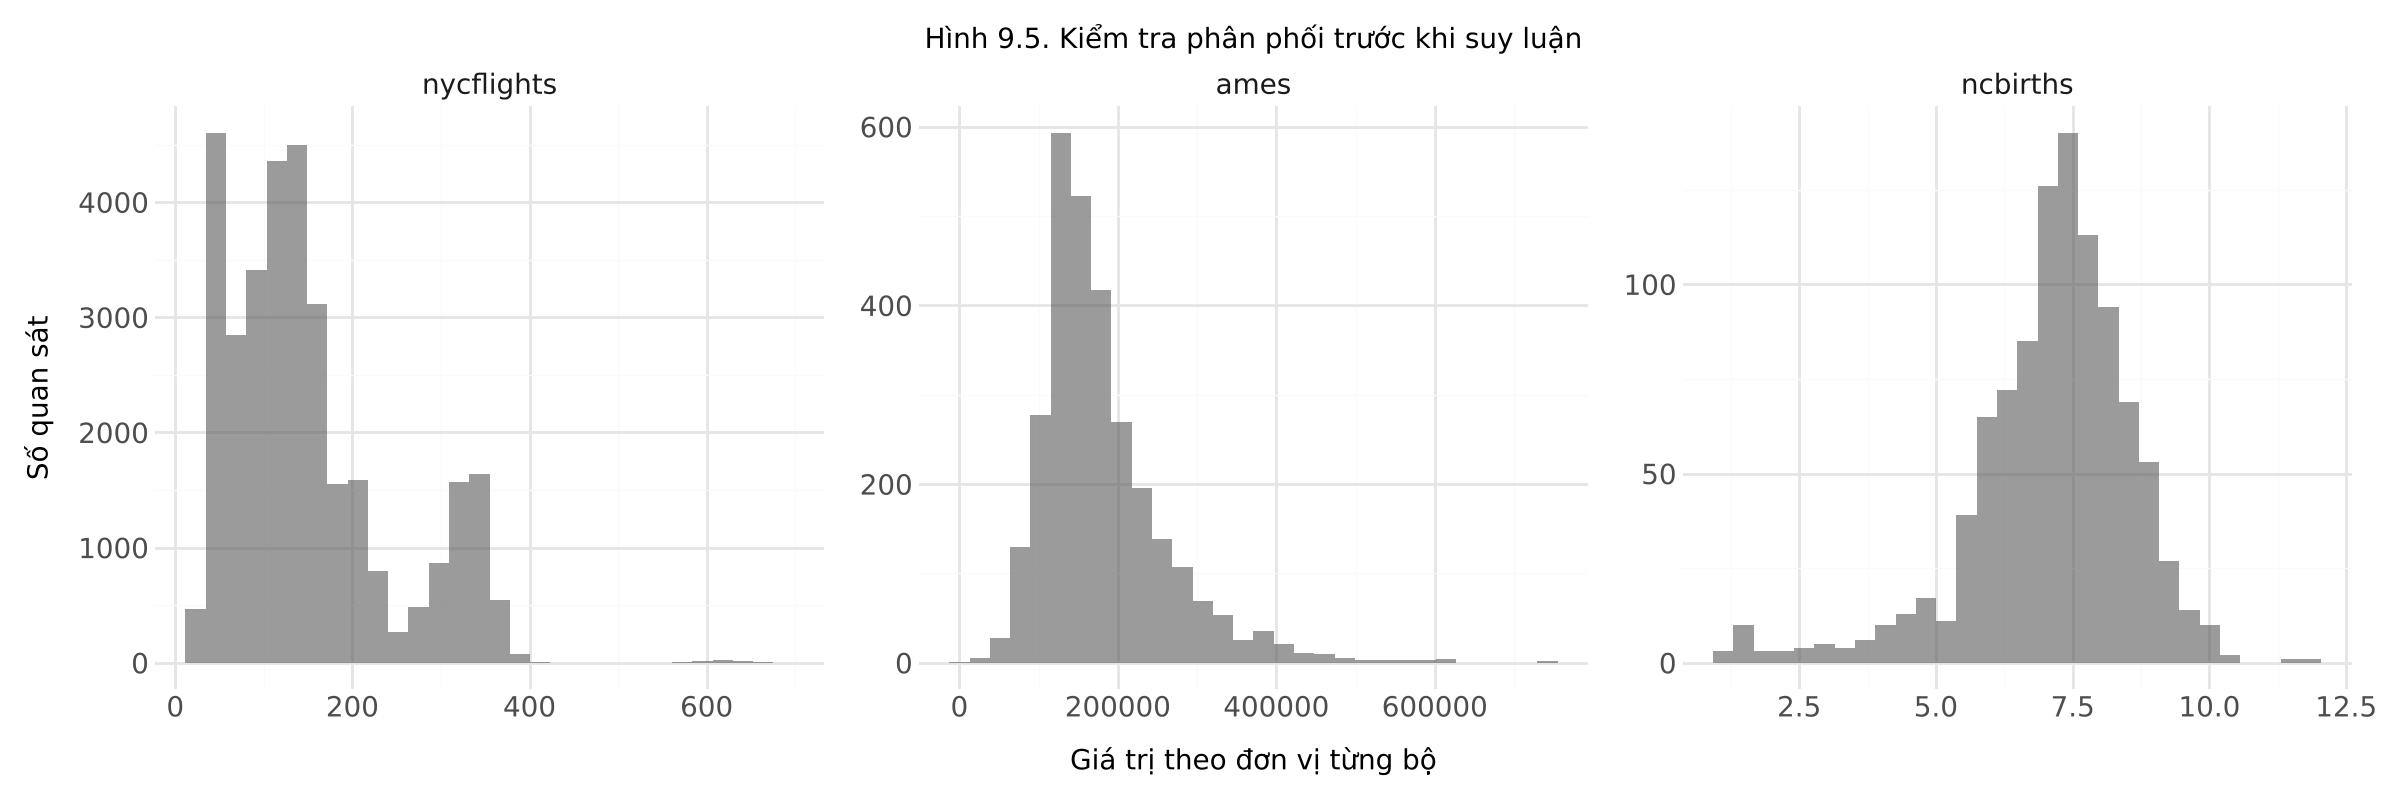

In [16]:
plot_data = real_distributions.copy()
plot_data['dataset'] = pd.Categorical(plot_data['dataset'], categories=list(pd.unique(plot_data['dataset'])), ordered=True)
p = (ggplot(plot_data, aes(x='value'))
     + geom_histogram(bins=30, alpha=0.6, position='identity')
     + facet_wrap('~dataset', scales='free', ncol=3)
     + labs(title='Hình 9.5. Kiểm tra phân phối trước khi suy luận', x='Giá trị theo đơn vị từng bộ', y='Số quan sát')
     + theme_minimal()
     + theme(figure_size=(12, max(4, 3.4*int(np.ceil(real_distributions['dataset'].nunique()/3)))), text=element_text(size=10)))
display(p)

**Thử đổi cỡ mẫu.** Quay lại ô `n_prop` ở mục 2, lần lượt đặt 50, 200, 1000, 4000 rồi chạy lại ô tính và ô hình. Ghi lại SE mô phỏng mỗi lần và kiểm tra quy luật: $n$ gấp 4 thì SE giảm một nửa.

## Tóm tắt và lỗi hay gặp

| Ý chính | Lỗi hay gặp |
|---|---|
| Tham số mô tả tổng thể, cố định; thống kê tính từ mẫu, đổi theo mẫu. | Gọi $\bar x$ là "trung bình thật". |
| Tăng cỡ mẫu giảm biến thiên, không sửa được chệch. | Nghĩ rằng mẫu thuận tiện rất lớn thì đại diện. |
| $SE(\bar X)=\sigma/\sqrt n$ là độ dao động của **trung bình**; $\sigma$ hay $s$ là độ dao động của **cá thể**. | Dùng SE để mô tả độ phân tán của dữ liệu. |
| Không chệch, vững, hiệu quả là ba tiêu chí khác nhau. | Nghĩ không chệch là đủ tốt (ví dụ "quan sát đầu"). |
| Khoảng $z$ khi biết $\sigma$; $z$ xấp xỉ khi $n$ lớn; $t_{n-1}$ khi tổng thể chuẩn và chưa biết $\sigma$. | Dùng 1,96 cho mẫu nhỏ; quên $df=n-1$. |
| "95%" là độ tin cậy của quy trình lập khoảng. | Nói "95% cá thể nằm trong khoảng" hoặc "$\mu$ có xác suất 95% nằm trong khoảng này". |
| Khoảng cho tỉ lệ cần cả $n\hat p\ge10$ và $n(1-\hat p)\ge10$. | Chỉ kiểm tra số thành công; bỏ bớt nhóm khỏi mẫu số. |
| Cỡ mẫu: $n\ge(z\sigma_0/E)^2$ hoặc $n\ge z^2p_0(1-p_0)/E^2$, luôn làm tròn lên; chưa biết thì $p_0=0{,}5$. | Làm tròn xuống; đoán $p_0$ tùy ý. |

## Tự kiểm tra và nối sang buổi tiếp theo

1. Một khảo sát online có 20.000 người trả lời, SE rất nhỏ. Khoảng tin cậy từ đó có đáng tin hơn một SRS 500 người không? Vì sao?
2. Nói bằng lời của bạn: "95%" trong "khoảng tin cậy 95%" là xác suất của cái gì?
3. Mẫu 12 bóng đèn có tuổi thọ trung bình 1.020 giờ, $s=60$ giờ; giả sử tuổi thọ chuẩn. Dùng $z$ hay $t$? Bậc tự do bao nhiêu?
4. Muốn biên sai số giảm từ 4 xuống 2 điểm phần trăm thì cỡ mẫu phải nhân lên bao nhiêu?

<details><summary>Gợi ý đáp án</summary>

1. Không nhất thiết. Người tự chọn tham gia khảo sát online có thể khác hệ thống với tổng thể (chệch chọn mẫu). SE nhỏ chỉ nói kết quả ít dao động; nó không sửa được chệch.
2. Là tỉ lệ số khoảng chứa tham số khi lặp lại quy trình lấy mẫu và lập khoảng rất nhiều lần. Nó không phải xác suất cho một khoảng đã tính.
3. Dùng $t$ vì chưa biết $\sigma$ và $n$ nhỏ; $df=11$, $t_{0{,}025,\,11}\approx2{,}201$. Khoảng: $1020\pm2{,}201\times60/\sqrt{12}\approx1020\pm38{,}1$ giờ.
4. $n$ tỉ lệ với $1/E^2$, nên $E$ giảm một nửa thì $n$ tăng gấp 4.

</details>

**Buổi sau.** Tuần 10 vẫn giữ một mẫu duy nhất, nhưng lấy mẫu lại **có hoàn lại từ chính mẫu đó** để ước lượng độ bất định khi không có công thức SE; đó là bootstrap. Sau đó buổi học chuyển sang kiểm định giả thuyết: ôn trước giả thuyết không $H_0$, đối thuyết $H_A$, p-value, sai lầm loại I và loại II.

## Nguồn học liệu

- Slide của học phần: `week09.pdf`; số trang được ghi trong metadata `source_pages` của từng ô.
- Đề cương UET.MAT1052: mục và chuẩn đầu ra của tuần tương ứng.
- STAT 20 bản dịch tiếng Việt: mục 5.1–5.2. Các hình tham khảo được nhúng thẳng vào notebook.
- Dữ liệu và cách chuyển đổi: `datasets/W09_W15_SOURCE_MANIFEST.json` và [hướng dẫn tuần 09–15](./README_W09_W15.md). Dữ liệu OpenIntro lấy từ [kho dữ liệu của nhà xuất bản](https://www.openintro.org/data/).